# Trajectory application

> Ambient: **scRNA_trajectory**

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import scanpy as sc
import pandas as pd
import numpy as np

DATASET = "Ffar2"
target_gene = "Ffar2"
sample_col = "sample"
condition_col = "condition"
celltype_col = "celltype"
counts_layer = "counts"
stage_order = ["G0", "G1", "G2", "G3", "G4", "G5a", "G5b", "G5c"]
condition_palette = {"WT": "#4C72B0", "KO": "#DD8452"}

output_dir = Path(f"/media/tahila/DADOS/HD/2605_scNeu/scNeu{DATASET}")
adata = sc.read_h5ad(f"{output_dir}/06sx.Neu{DATASET}_annotated.h5ad")
ad_traj = adata.copy()

# Step 1 — Build and validate the global maturation topology with diffusion maps and PAGA

### Goal

Before calculating pseudotime, we first ask whether the **transcriptional structure of the dataset is consistent with the known neutrophil maturation sequence**:

**G0 → G1 → G2 → G3 → G4 → G5a/G5b → G5c**

where `G5a` and `G5b` represent alternative states emerging after G4 and both subsequently connect to G5c.

This step is important because trajectory inference should not be used simply to force cells into a predefined biological order. Instead, the topology inferred from transcriptomic similarity should first be checked against prior biological knowledge [Wolf, 2019; Haghverdi, 2016].

### Why use diffusion maps?

Diffusion maps represent cells according to their connectivity through the cell–cell neighborhood graph rather than only their Euclidean distance in PCA space. This makes them particularly suitable for continuous biological processes such as differentiation and maturation [Haghverdi, 2016].

The diffusion representation will later also provide the basis for **Diffusion Pseudotime (DPT)**.

### Why use PAGA?

**PAGA (Partition-based Graph Abstraction)** summarizes the single-cell neighborhood graph into a simpler graph in which:

* each node represents a cell population;
* edges represent the statistical connectivity between populations;
* stronger edges indicate stronger evidence that two populations are connected in the underlying single-cell manifold;
* weak/spurious connections can be removed by thresholding.

Unlike methods that force the data into a tree, PAGA can represent more complex topologies, including branching, disconnected regions, and non-tree structures [Wolf, 2019]. This is particularly useful here because `G5a` and `G5b` form alternative states rather than a simple strictly linear sequence.

At this stage, **PAGA does not establish directionality**. An edge between G3 and G4 means that these populations are transcriptionally connected; the biological direction `G3 → G4` comes from prior knowledge and will later be incorporated through the definition of G0 as the trajectory root.

### Representation used in this dataset

For this dataset, the trajectory will be inferred jointly using cells from both WT and KO. Therefore, the low-dimensional representation used to construct the graph should represent the **shared biological manifold across conditions**.

The existing integrated PCA can be used for this purpose, provided that `X_pca` corresponds to the Seurat-anchor-integrated representation used in the original analysis.

Importantly, the integrated representation is appropriate for **constructing the trajectory geometry**, but it should not later be used as the expression matrix for testing gene-expression differences between WT and KO. Gene-level statistical analyses should return to non-integrated expression/count data.

The categorical ordering is mainly useful for consistent plotting and summaries. It **does not imply that G5a precedes G5b**; they are biologically parallel states.

In [2]:
### Function 1 — Compute diffusion maps and PAGA

def ComputeDiffusionPaga(
    adata,
    group_col,
    use_rep="X_pca",
    n_neighbors=15,
    n_diffmap=15,
    initial_neighbors_key="trajectory_initial_neighbors",
    trajectory_neighbors_key="trajectory_neighbors",
    random_state=42,
):
    """
    adata : AnnData --> Annotated single-cell dataset.
    group_col : str --> Column defining groups represented as PAGA nodes.
    use_rep : str --> Initial low-dimensional representation.
    n_neighbors : int --> Number of neighbors used for graph construction.
    n_diffmap : int --> Number of diffusion components.
    initial_neighbors_key : str --> Key used for the initial neighbor graph.
    trajectory_neighbors_key : str --> Key used for the diffusion-space neighbor graph.
    random_state : int --> Random seed.
    """
    # check that the group column (PAGA nodes) exists in adata.obs
    if group_col not in adata.obs:
        raise KeyError(f"{group_col} not found in adata.obs.")

    # check that the initial low-dimensional representation (e.g. X_pca) exists in adata.obsm
    if use_rep not in adata.obsm:
        raise KeyError(f"{use_rep} not found in adata.obsm.")

    # Initial cell-cell graph
    # build the initial neighbor graph from use_rep (e.g. the integrated PCA)
    sc.pp.neighbors(
        adata,
        n_neighbors=n_neighbors,
        use_rep=use_rep,
        key_added=initial_neighbors_key,
        random_state=random_state,
    )

    # Diffusion representation
    # compute the diffusion map from the initial neighbor graph
    sc.tl.diffmap(
        adata,
        n_comps=n_diffmap,
        neighbors_key=initial_neighbors_key,
        random_state=random_state,
    )

    # Neighborhood graph in diffusion space
    # rebuild the neighbor graph, now using the diffusion space (X_diffmap)
    sc.pp.neighbors(
        adata,
        n_neighbors=n_neighbors,
        use_rep="X_diffmap",
        key_added=trajectory_neighbors_key,
        random_state=random_state,
    )

    # PAGA topology
    # compute the PAGA topology (connectivity between groups) using the diffusion-space graph
    sc.tl.paga(
        adata,
        groups=group_col,
        neighbors_key=trajectory_neighbors_key,
    )

    # store the parameters used in this step, for traceability and reproducibility
    adata.uns["trajectory_params"] = {
        "group_col": group_col,
        "use_rep": use_rep,
        "n_neighbors": n_neighbors,
        "n_diffmap": n_diffmap,
        "initial_neighbors_key": initial_neighbors_key,
        "trajectory_neighbors_key": trajectory_neighbors_key,
        "random_state": random_state,
    }

In [3]:
### Application
ComputeDiffusionPaga(
    adata=ad_traj,
    group_col="celltype",
    use_rep="X_pca",
    n_neighbors=15,
    n_diffmap=15,
)

In [4]:
### Function 3 — Plot the PAGA topology

import matplotlib.pyplot as plt  # needed to control the figure/axis of the plot


def PlotPagaTrajectory(
    adata,
    group_col,
    threshold=0.03,
    figsize=(6, 6),
):
    """
    adata : AnnData --> Dataset containing a computed PAGA graph.
    group_col : str --> Group annotation represented by PAGA nodes.
    threshold : float --> Minimum connectivity displayed.
    figsize : tuple --> Figure size.
    """
    # create figure and axis with the given size
    fig, ax = plt.subplots(figsize=figsize)

    # plot the PAGA graph, showing only connections above the connectivity threshold
    sc.pl.paga(
        adata,
        color=group_col,
        threshold=threshold,
        frameon=False,
        ax=ax,
        show=False,
    )

    # display the figure
    plt.show()

    # return the axis, so it can be customized further outside the function
    return ax

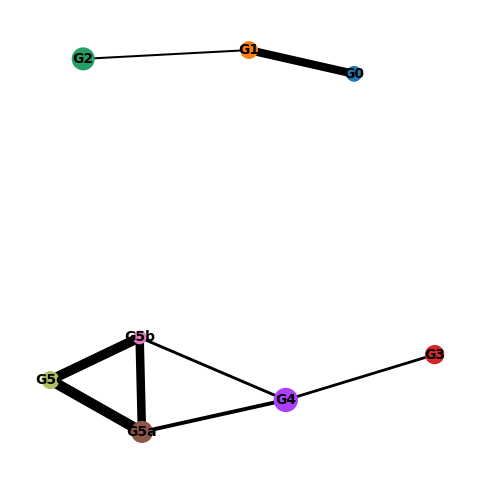

<Axes: >

In [5]:
### Application
PlotPagaTrajectory(
    adata=ad_traj,
    group_col="celltype",
    threshold=0.03,
)

### What should we expect?

A biologically coherent topology would approximately support:

```text
G0 — G1 — G2 — G3 — G4
                     /  \
                   G5a  G5b
                     \  /
                     G5c
```

It does **not need to reproduce this exact drawing**. The graph layout itself is arbitrary; what matters is the **pattern and relative strength of the edges**.

Particularly important observations will be:

* whether G0 connects primarily to early states;
* whether G1–G4 form a broadly sequential structure;
* whether G5a and G5b connect to G4;
* whether G5c connects to the late populations;
* whether unexpectedly strong shortcuts such as `G0–G5c` occur;
* whether any stage becomes disconnected.

We should inspect this result **before calculating pseudotime**. If the PAGA topology is biologically coherent, **Step 2 will define a representative G0 root cell and calculate DPT pseudotime** [Haghverdi, 2016; Wolf, 2019].


# Step 2 — Define the trajectory root and compute Diffusion Pseudotime (DPT)

### Goal

After confirming with PAGA that the global transcriptomic topology is compatible with the expected neutrophil maturation structure, the next step is to obtain a **continuous maturation coordinate** for each cell.

For this dataset, the biological starting population is already known:

**G0 → G1 → G2 → G3 → G4 → G5a/G5b → G5c**

Therefore, we do not need to infer which population represents the beginning of the trajectory. We only need to select a representative cell within **G0** and use it as the DPT root.

**Diffusion Pseudotime (DPT)** orders cells according to diffusion-based distances from a specified root cell, providing a continuous coordinate along the inferred cellular manifold [Haghverdi, 2016]. DPT requires a diffusion map, which was already calculated in Step 1. ([Scanpy][1])

The resulting pseudotime is a **relative transcriptional progression**, not chronological time. A value of 0.8 does not mean that a cell is twice as old as a cell at 0.4 [Haghverdi, 2016].

### Why DPT is appropriate here

DPT is sufficient for the present goal because:

* G0 is a biologically defined starting state;
* we want one continuous maturation axis shared by WT and KO;
* fate probabilities are not required;
* the `G5a/G5b` branching structure is assessed separately with PAGA.

Scanpy currently recommends using DPT primarily for pseudotime ordering and handling branching structure separately with PAGA rather than relying on the older hierarchical branching functionality of DPT [Wolf, 2019]. ([Scanpy][1])

---

### Select a representative G0 root cell

Scanpy technically requires only **one root-cell index** in:

```python
ad_traj.uns["iroot"]
```

The official Scanpy trajectory tutorial selects a biologically defined stem/progenitor cell and then runs DPT. ([Scanpy][2])

Because G0 contains many cells, we will avoid selecting an arbitrary or peripheral G0 cell. Instead, we select the G0 cell closest to the median position of G0 in diffusion space.

This is a **practical robustness heuristic**, not a requirement of the DPT method.

This helper is generic enough to keep in `sctools`, since it can also be reused whenever a representative cell from an annotated population is needed.

In [6]:
def SelectRepresentativeCell(
    adata,
    group_col,
    group,
    rep_key="X_diffmap",
    n_components=10,
):
    """
    adata : AnnData --> Annotated single-cell dataset.
    group_col : str --> Column containing population annotations.
    group : str --> Population used for representative-cell selection.
    rep_key : str --> Low-dimensional representation used for selection.
    n_components : int --> Number of dimensions used to define the population center.
    """
    mask = adata.obs[group_col].astype(str).eq(group).to_numpy()

    cells = adata.obs_names[mask]
    X = adata.obsm[rep_key][mask]

    if len(cells) == 0:
        raise ValueError(f"No cells found for group: {group}")

    # Skip the first diffusion component
    start = 1 if rep_key == "X_diffmap" else 0
    X = X[:, start:start + n_components]

    center = np.median(X, axis=0)
    distances = np.linalg.norm(X - center, axis=1)

    return cells[np.argmin(distances)]

In [7]:
### Application
root_cell = SelectRepresentativeCell(
    adata=ad_traj,
    group_col="celltype",
    group="G0",
    rep_key="X_diffmap",
    n_components=10,
)

print("Root cell:", root_cell)
print("Cell type:", ad_traj.obs.loc[root_cell, "celltype"])

Root cell: 36711955-K1
Cell type: G0


The important check is simply:

```text
Cell type: G0
```

## Compute DPT

I would **not create a custom `sctools` wrapper for this step**. `scanpy.tl.dpt()` already performs exactly what we need, so wrapping it would only duplicate Scanpy.

Set the selected cell as the root:

```python
ad_traj.uns["iroot"] = ad_traj.obs_names.get_loc(root_cell)
```

Then calculate DPT:


In [8]:
ad_traj.uns["iroot"] = ad_traj.obs_names.get_loc(root_cell)

sc.tl.dpt(
    ad_traj,
    n_dcs=10,
    n_branchings=0,
    neighbors_key="trajectory_neighbors",
)

Scanpy stores the result directly in:

```python
ad_traj.obs["dpt_pseudotime"]
```

`n_dcs=10` is the current Scanpy default for the number of diffusion components contributing to DPT. Since we computed 15 diffusion components in Step 1, there are sufficient components available for this calculation. ([Scanpy][1])

We explicitly use:

```python
neighbors_key="trajectory_neighbors"
```

so DPT operates on the diffusion-space neighborhood graph created in Step 1 rather than another neighbor graph that may already exist in the `AnnData`. Scanpy supports this through the `neighbors_key` argument. ([Scanpy][3])

And:

```python
n_branchings=0
```

because we are using **PAGA for topology/branch structure** and DPT only for the continuous pseudotime coordinate.

---

## Quick visualization

At this stage, only perform a basic sanity check:

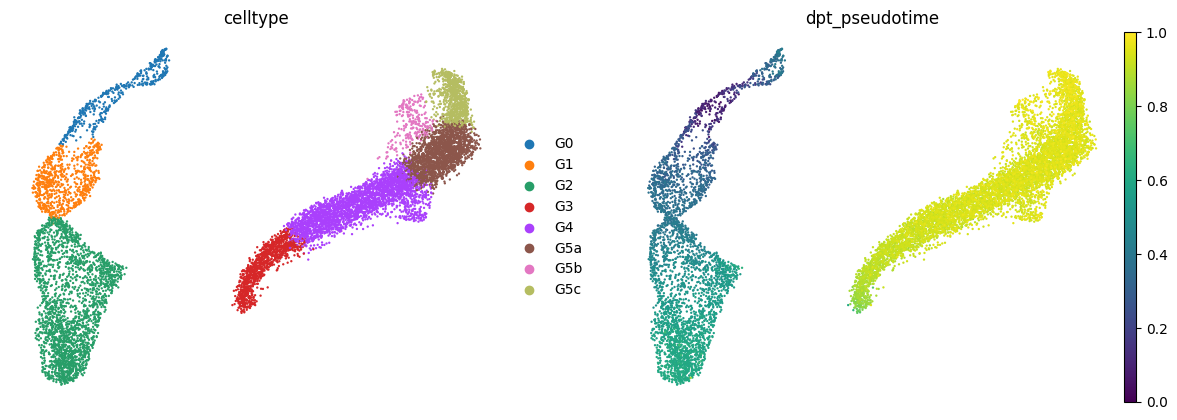

In [9]:
sc.pl.umap(
    ad_traj,
    color=["celltype", "dpt_pseudotime"],
    cmap="viridis",
    frameon=False,
    ncols=2,
)

We expect low DPT values around G0 and progressively higher values toward the mature populations.

The UMAP itself does **not** define the trajectory; it is only being used to visualize the DPT values on the existing embedding.

---

### Output of this step

The only new variable required downstream is:

```python
ad_traj.obs["dpt_pseudotime"]
```

---

### Operational summary of Step 2:

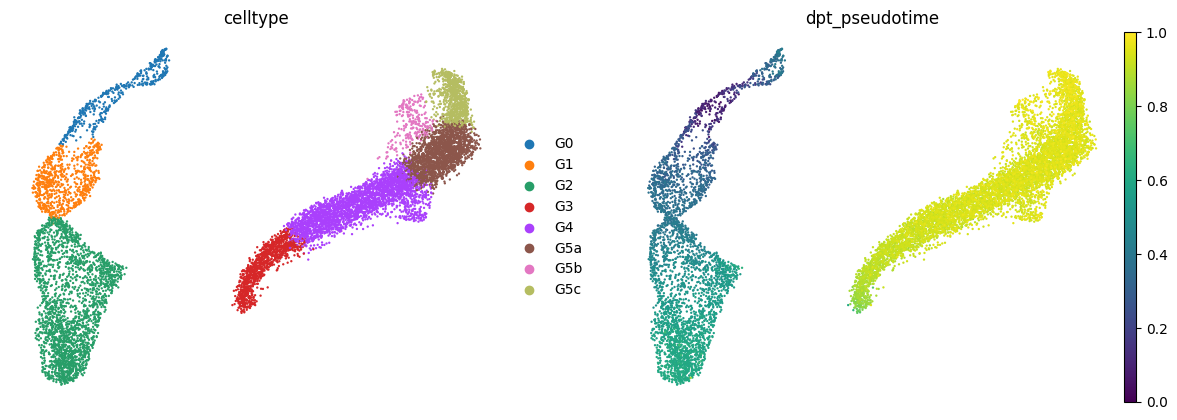

In [10]:
root_cell = SelectRepresentativeCell(
    ad_traj,
    group_col="celltype",
    group="G0",
    rep_key="X_diffmap",
)

ad_traj.uns["iroot"] = ad_traj.obs_names.get_loc(root_cell)

sc.tl.dpt(
    ad_traj,
    n_dcs=10,
    n_branchings=0,
    neighbors_key="trajectory_neighbors",
)

sc.pl.umap(
    ad_traj,
    color=["celltype", "dpt_pseudotime"],
    cmap="viridis",
    frameon=False,
    ncols=2,
)

# Step 3 — Validate the biological coherence of the inferred pseudotime

### Goal

Before using DPT in downstream analyses, we need to verify that the inferred continuous coordinate is **consistent with the known neutrophil maturation process**:

**G0 → G1 → G2 → G3 → G4 → G5a/G5b → G5c**

This step is a **sanity/biological-consistency check**, not an independent validation of the cell annotations.

Because the maturation labels were themselves defined from transcriptional information, agreement between `celltype` and DPT should not be interpreted as independent experimental evidence that the trajectory is correct. Instead, we are checking that the continuous manifold inferred by DPT is compatible with the biological structure already established for the dataset [Haghverdi, 2016; Wolf, 2019].

We mainly want to confirm that:

* G0 occupies the beginning of pseudotime;
* G1–G4 progressively move toward later pseudotime;
* G5a and G5b occur in late regions without requiring one to precede the other;
* G5c occupies the latest portion of the maturation continuum;
* the same general ordering is recognizable in all biological samples.

Some overlap between adjacent populations is expected because differentiation and maturation are continuous processes rather than perfectly discrete transcriptional states [Haghverdi, 2016].

---

## 3.1 — Visualize pseudotime on the existing UMAP

The UMAP is used here only for visualization. DPT was calculated from the diffusion-based neighborhood graph, not from the UMAP coordinates.



[1]: https://scanpy.readthedocs.io/en/latest/api/scanpy.tl.dpt.html?utm_source=chatgpt.com "scanpy.tl.dpt - Read the Docs"
[2]: https://scanpy.readthedocs.io/en/latest/tutorials/trajectories/paga-paul15.html?utm_source=chatgpt.com "Trajectory inference for hematopoiesis in mouse - Scanpy"
[3]: https://scanpy.readthedocs.io/en/stable/api/scanpy.tl.dpt.html?utm_source=chatgpt.com "scanpy.tl.dpt - Read the Docs"


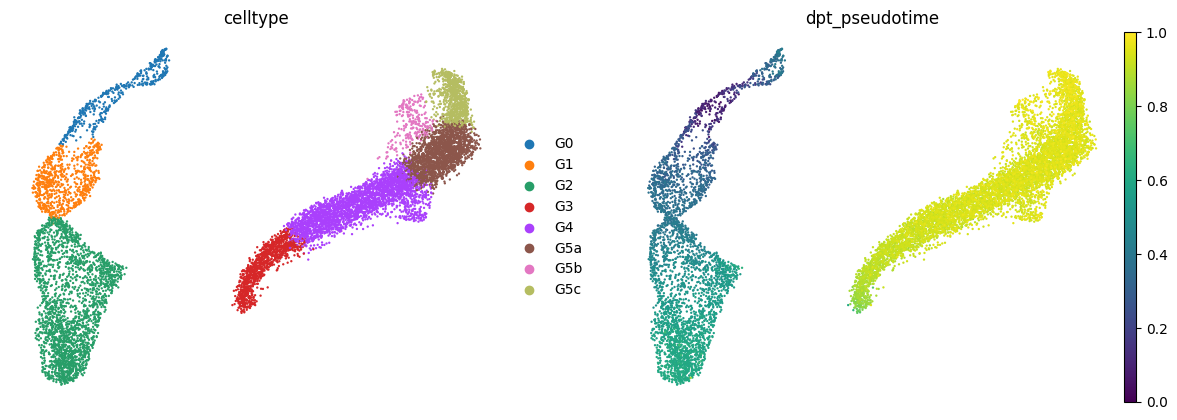

In [11]:
sc.pl.umap(
    ad_traj,
    color=["celltype", "dpt_pseudotime"],
    cmap="viridis",
    frameon=False,
    ncols=2,
)

We should see a broadly continuous transition from low pseudotime around G0 toward higher values in the mature populations.

A perfect geometric gradient on UMAP is **not required**, because UMAP can distort global distances and topology [Wolf, 2019].

---

## 3.2 — Inspect pseudotime distributions across maturation stages

The most informative plot for this step is the distribution of DPT values within each known maturation state.


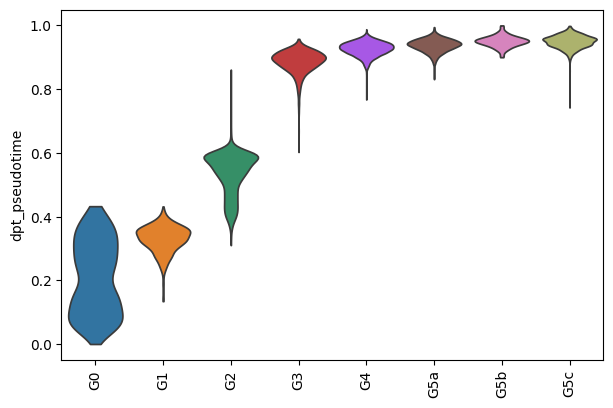

In [12]:
sc.pl.violin(
    ad_traj,
    keys="dpt_pseudotime",
    groupby="celltype",
    order=stage_order,
    rotation=90,
    stripplot=False,
)

The expected pattern is approximately:

```text
G0 < G1 < G2 < G3 < G4 < G5a/G5b < G5c
```

However, we should **not expect complete separation** between stages.

In particular, `G5a` and `G5b` are alternative late states, so their distributions can overlap considerably and their median pseudotimes do not need to be identical.

We should also avoid interpreting the categorical ordering:

```text
G5a → G5b
```

because that transition is not part of the biological model.

---

## 3.3 — Summarize pseudotime by maturation stage

A simple table is enough; there is no need for a dedicated `sctools` function.

In [13]:
pseudotime_summary = (
    ad_traj.obs
    .groupby("celltype", observed=True)["dpt_pseudotime"]
    .agg(
        n="size",
        median="median",
        mean="mean",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reindex(stage_order)
)

pseudotime_summary

,n,median,mean,q25,q75
celltype,,,,,
G0,455,0.206337,0.208375,0.102357,0.311639
G1,772,0.335717,0.329710,0.306758,0.358875
G2,2328,0.554106,0.534572,0.495110,0.586731
G3,1102,0.892260,0.885809,0.869547,0.909911
G4,2924,0.929060,0.927021,0.913805,0.942669
G5a,1929,0.939908,0.937968,0.926335,0.951631
G5b,245,0.950609,0.950272,0.940154,0.961026
G5c,815,0.950925,0.949393,0.937189,0.962510


The median is particularly useful for checking the overall progression, while `q25` and `q75` show how much neighboring states overlap.

---

## 3.4 — Check consistency across biological samples

Because the trajectory will later be used to compare WT and KO, we should verify that the maturation ordering is not driven by only one mouse.

Again, a simple summary is sufficient.


In [14]:
pseudotime_by_sample = (
    ad_traj.obs
    .groupby(
        ["sample", "celltype"],
        observed=True,
    )["dpt_pseudotime"]
    .median()
    .unstack("celltype")
    .reindex(columns=stage_order)
)

pseudotime_by_sample

celltype,G0,G1,G2,G3,G4,G5a,G5b,G5c
sample,,,,,,,,
K1,0.162759,0.338133,0.560403,0.894307,0.932050,0.940226,0.955729,0.950792
K2,0.208792,0.331707,0.548423,0.894870,0.930055,0.940887,0.953748,0.955224
W1,0.206337,0.313132,0.572426,0.889347,0.928222,0.940760,0.948540,0.948154
W2,0.224673,0.353671,0.545134,0.890815,0.927021,0.937654,0.947547,0.949627


Each row represents one biological sample.

We want the same broad progression to be recognizable in all four animals:

```text
G0 → G1 → G2 → G3 → G4 → late states → G5c
```

The absolute median pseudotime values do not need to be identical between animals.

---

## 3.5 — Optional: check WT and KO separately

This is useful as a quick visualization before moving to condition comparisons.

In [15]:
pseudotime_by_condition = (
    ad_traj.obs
    .groupby(
        ["condition", "celltype"],
        observed=True,
    )["dpt_pseudotime"]
    .median()
    .unstack("celltype")
    .reindex(columns=stage_order)
)

pseudotime_by_condition

celltype,G0,G1,G2,G3,G4,G5a,G5b,G5c
condition,,,,,,,,
KO,0.197011,0.333650,0.551981,0.894726,0.930653,0.940634,0.953926,0.953642
WT,0.214823,0.337329,0.555190,0.890362,0.927615,0.939193,0.947666,0.948454


This does **not test whether WT and KO differ statistically**. It only verifies that both conditions are being represented along the same biologically interpretable maturation axis.

If these results show a coherent **G0 → G5c maturation continuum in all four samples**, we consider the DPT axis sufficiently supported for downstream use [Haghverdi, 2016].
---

## Minimal operational Step 3

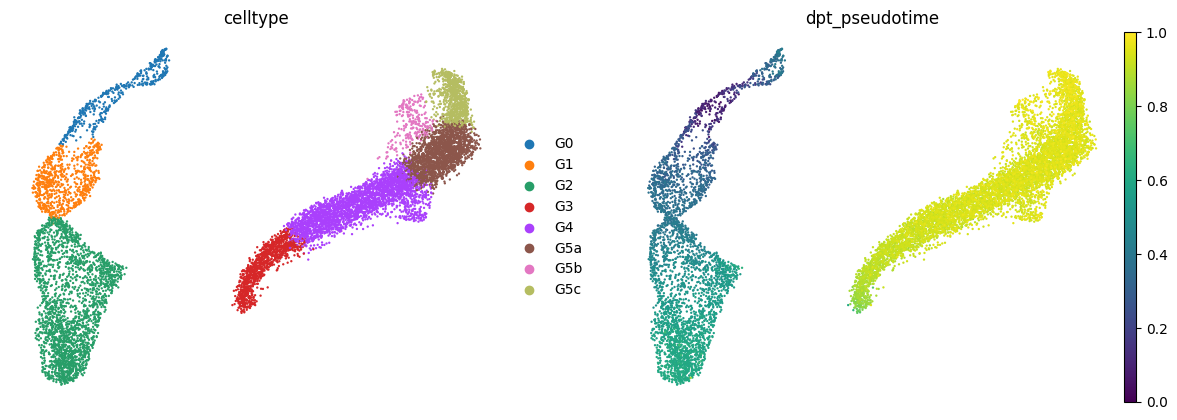

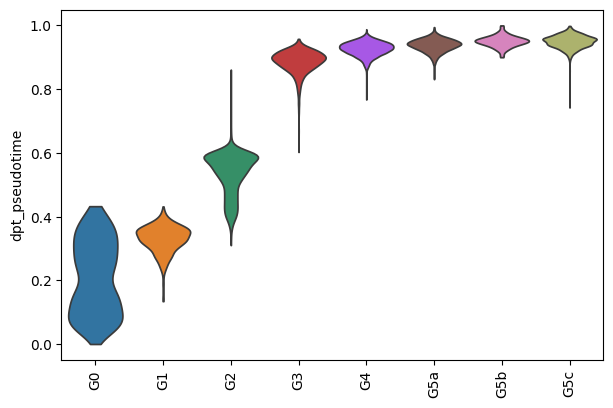

,n,median,q25,q75
celltype,,,,
G0,455,0.206337,0.102357,0.311639
G1,772,0.335717,0.306758,0.358875
G2,2328,0.554106,0.495110,0.586731
G3,1102,0.892260,0.869547,0.909911
G4,2924,0.929060,0.913805,0.942669
G5a,1929,0.939908,0.926335,0.951631
G5b,245,0.950609,0.940154,0.961026
G5c,815,0.950925,0.937189,0.962510


celltype,G0,G1,G2,G3,G4,G5a,G5b,G5c
sample,,,,,,,,
K1,0.162759,0.338133,0.560403,0.894307,0.932050,0.940226,0.955729,0.950792
K2,0.208792,0.331707,0.548423,0.894870,0.930055,0.940887,0.953748,0.955224
W1,0.206337,0.313132,0.572426,0.889347,0.928222,0.940760,0.948540,0.948154
W2,0.224673,0.353671,0.545134,0.890815,0.927021,0.937654,0.947547,0.949627


In [16]:
# DPT on UMAP
sc.pl.umap(
    ad_traj,
    color=["celltype", "dpt_pseudotime"],
    cmap="viridis",
    frameon=False,
    ncols=2,
)

# DPT distribution across maturation stages
sc.pl.violin(
    ad_traj,
    keys="dpt_pseudotime",
    groupby="celltype",
    order=stage_order,
    rotation=90,
    stripplot=False,
)

# Stage-level summary
pseudotime_summary = (
    ad_traj.obs
    .groupby("celltype", observed=True)["dpt_pseudotime"]
    .agg(
        n="size",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reindex(stage_order)
)

display(pseudotime_summary)

# Check each biological replicate
pseudotime_by_sample = (
    ad_traj.obs
    .groupby(["sample", "celltype"], observed=True)["dpt_pseudotime"]
    .median()
    .unstack("celltype")
    .reindex(columns=stage_order)
)

display(pseudotime_by_sample)

# Step 4 — TradeSeq - Identify condition-dependent gene dynamics along pseudotime

Sim. Vamos **voltar exatamente ao núcleo que já rodou no seu computador e gerou os plots de Ffar2, Fosb e Dusp1**. Não vou incluir agora `l2fc`, `predictSmooth`, métricas de separação, `converged`, `sce=True` nem uma segunda chamada do `conditionTest`.

O Step 4 fica apenas:

```text
raw counts + DPT + condition
        ↓
min_cells = 20
        ↓
fitGAM()
        ↓
conditionTest()
        ↓
BH correction
        ↓
PlotTradeSeqConditionGene()
```

O `min_cells=20` continua sendo **nosso filtro computacional**, não uma regra do tradeSeq. O restante é o teste oficial do tradeSeq para modelar expressão ao longo do pseudotime [Van den Berge, 2020].

---

## Markdown cell

````markdown
# Step 4 — Identify condition-dependent gene dynamics along pseudotime

### Goal

The main question is:

> **Which genes show different expression dynamics along neutrophil maturation between WT and KO?**

Instead of comparing WT and KO independently at discrete maturation stages, this analysis uses the **continuous DPT pseudotime** calculated in Steps 1–3.

For each gene, condition-specific expression trajectories are modeled along pseudotime:

```text
WT: expression = fWT(pseudotime)
KO: expression = fKO(pseudotime)
````

`tradeSeq` models gene counts along pseudotime using negative-binomial generalized additive models (NB-GAMs) [Van den Berge, 2020].

The analysis uses raw counts and does **not require genes to be significant in the previous stage-specific differential-expression analysis**.

### Input

```text
ad_traj.layers["QC_filtered"]  → raw counts
ad_traj.obs["dpt_pseudotime"] → continuous maturation coordinate
ad_traj.obs["condition"]       → WT / KO
```

Because a single common maturation trajectory is modeled, all cells receive lineage weight equal to `1`.

### Gene filtering

Genes detected in fewer than 20 cells are excluded before GAM fitting.

This is a **practical computational filter**, not an official tradeSeq threshold or a universal biological cutoff. Its purpose is to avoid fitting complex GAMs to extremely sparse genes with little information about continuous expression dynamics.

### Statistical interpretation

`conditionTest()` tests whether the fitted expression trajectories differ between conditions.

Because the model is fitted at the cell level, these results should be interpreted primarily as **trajectory-based evidence for gene discovery and prioritization**, rather than as replicate-aware evidence of a genotype effect.

The existing pseudobulk analysis remains complementary evidence for reproducibility across biological samples.

````

---

# 4.1 Condition-dependent tradeSeq model

Essa é a **versão que devemos manter agora**:

In [18]:
def RunTradeSeqConditionDynamics(
    adata,
    counts_layer,
    pseudotime_col="dpt_pseudotime",
    condition_col="condition",
    condition_order=("WT", "KO"),
    min_cells=20,
    nknots=6,
    l2fc=0.0,
    n_cpus=4,
    seed=42,
):
    """
    Fit tradeSeq condition-specific NB-GAMs and run conditionTest.

    adata : AnnData --> Single-cell dataset containing raw counts and pseudotime.
    counts_layer : str --> Layer containing raw counts.
    pseudotime_col : str --> Column containing continuous pseudotime.
    condition_col : str --> Column containing experimental conditions.
    condition_order : tuple[str] --> Ordered condition levels.
    min_cells : int --> Minimum cells detecting a gene before GAM fitting.
    nknots : int --> Number of knots used by tradeSeq GAMs.
    n_cpus : int --> Number of CPUs used by tradeSeq.
    seed : int --> Random seed.
    l2fc : float --> Minimum log2 fold-change threshold used by conditionTest.

    Returns
    -------
    dict --> conditionTest results, fitted tradeSeq model, counts matrix and fitted genes.
    """
    import numpy as np
    import pandas as pd
    from scipy import sparse
    from rpy2 import robjects as ro
    from rpy2.robjects import pandas2ri
    from rpy2.robjects.conversion import localconverter

    # Keep cells with complete trajectory metadata
    mask = adata.obs[[pseudotime_col, condition_col]].notna().all(axis=1).to_numpy()

    X = adata.layers[counts_layer][mask]
    cells = adata.obs_names[mask].astype(str)

    # CUSTOM preprocessing: remove extremely sparse genes
    if sparse.issparse(X):
        detected = np.asarray((X > 0).sum(axis=0)).ravel()
    else:
        detected = (np.asarray(X) > 0).sum(axis=0)

    keep = detected >= min_cells

    genes = adata.var_names[keep].astype(str)
    X = X[:, keep]

    if not sparse.issparse(X):
        X = sparse.csr_matrix(X)

    # tradeSeq expects genes x cells
    X = X.T.tocoo()

    # Transfer the sparse count matrix to R without densifying it
    ro.globalenv["i_idx"] = ro.IntVector((X.row + 1).astype(int))
    ro.globalenv["j_idx"] = ro.IntVector((X.col + 1).astype(int))
    ro.globalenv["x_val"] = ro.FloatVector(X.data.astype(float))
    ro.globalenv["n_genes"] = int(X.shape[0])
    ro.globalenv["n_cells"] = int(X.shape[1])
    ro.globalenv["gene_names"] = ro.StrVector(genes.tolist())
    ro.globalenv["cell_names"] = ro.StrVector(cells.tolist())

    # Transfer pseudotime and experimental conditions
    pseudotime = adata.obs.loc[cells, pseudotime_col].astype(float).to_numpy()
    conditions = adata.obs.loc[cells, condition_col].astype(str).to_numpy()

    ro.globalenv["pseudotime_vec"] = ro.FloatVector(pseudotime)
    ro.globalenv["condition_vec"] = ro.StrVector(conditions)
    ro.globalenv["condition_levels"] = ro.StrVector(list(condition_order))
    ro.globalenv["nknots_run"] = int(nknots)
    ro.globalenv["n_cpus_run"] = int(n_cpus)
    ro.globalenv["seed_run"] = int(seed)
    ro.globalenv["l2fc_run"] = float(l2fc)

    ro.r(
        """
        suppressPackageStartupMessages({
            library(Matrix)
            library(tradeSeq)
            library(BiocParallel)
        })

        # Reconstruct the sparse raw-count matrix
        counts_mat <- sparseMatrix(
            i=i_idx,
            j=j_idx,
            x=x_val,
            dims=c(n_genes, n_cells)
        )

        rownames(counts_mat) <- gene_names
        colnames(counts_mat) <- cell_names

        # One pseudotime column represents one lineage
        pseudotime_mat <- matrix(pseudotime_vec, ncol=1)

        # All cells belong to the same maturation lineage
        cell_weights <- matrix(1, nrow=n_cells, ncol=1)

        # Define experimental conditions
        conditions <- factor(condition_vec, levels=condition_levels)

        set.seed(seed_run)

        bp <- MulticoreParam(workers=n_cpus_run)

        # Fit condition-specific NB-GAM smoothers
        trade_model <- fitGAM(
            counts=counts_mat,
            pseudotime=pseudotime_mat,
            cellWeights=cell_weights,
            conditions=conditions,
            nknots=nknots_run,
            verbose=FALSE,
            parallel=n_cpus_run > 1,
            BPPARAM=bp
        )

        # Test whether WT and KO fitted trajectories differ
        condition_res <- as.data.frame(
            conditionTest(
                trade_model,
                global=TRUE,
                pairwise=FALSE,
                l2fc=l2fc_run
            )
        )

        condition_res$gene <- rownames(condition_res)

        # Benjamini-Hochberg multiple-testing correction
        condition_res$padj <- p.adjust(condition_res$pvalue, method="BH")
        """
    )

    # Convert tradeSeq results back to pandas
    with localconverter(ro.default_converter + pandas2ri.converter):
        results = ro.conversion.rpy2py(ro.globalenv["condition_res"])

    results = pd.DataFrame(results)
    results = results.sort_values(["padj", "pvalue", "waldStat"], ascending=[True, True, False], na_position="last").reset_index(drop=True)

    return {
        "results": results,
        "model": ro.globalenv["trade_model"],
        "counts": ro.globalenv["counts_mat"],
        "genes": genes.tolist(),
    }

In [19]:
# trade_condition = RunTradeSeqConditionDynamics(
#     adata=ad_traj,
#     counts_layer="QC_filtered",
#     pseudotime_col="dpt_pseudotime",
#     condition_col="condition",
#     condition_order=("WT", "KO"),
#     min_cells=20,
#     nknots=6,
#     l2fc=0,
#     n_cpus=2,
#     seed=42,
# )

# condition_dynamics = trade_condition["results"]

# display(condition_dynamics.head(30))

## 4.2 Inspect the results - Condition-dependent genes

The resulting table ranks genes according to the evidence that their fitted expression trajectories differ between WT and KO.

Main columns:

- `waldStat`: Wald statistic from `conditionTest()`.
- `pvalue`: raw p-value.
- `padj`: Benjamini-Hochberg adjusted p-value.

A low `padj` indicates statistical evidence that the WT and KO fitted trajectories are not identical.

However, statistical significance does not necessarily imply a large visual difference between the fitted curves. Therefore, genes of interest should also be inspected using the fitted trajectory plots.
```

In [20]:
# condition_candidates = condition_dynamics.query("padj < 0.05").copy()

# print(f"Candidate genes: {condition_candidates.shape[0]}")
# display(condition_candidates.head(30))

In [21]:
# ### Candidate table
# condition_candidates = condition_dynamics.query("padj < 0.05").copy()

# print(f"Candidate genes: {condition_candidates.shape[0]}")
# display(condition_candidates.head(30))

In [22]:
# ### Candidate table sorted by |df|
# display(
#     condition_candidates.sort_values(
#         "df",
#         key=lambda x: x.abs(),
#         ascending=False,
#     )
# )

## 4.3 Visualize fitted WT and KO curves


`tradeSeq::plotSmoothers()` displays the observed expression values together with the condition-specific smoothers fitted along pseudotime.

This visualization is important because genes with very small adjusted p-values may still display relatively modest differences between WT and KO.

The plots therefore complement the statistical ranking by showing:

- the magnitude of the WT–KO separation;
- where along pseudotime the difference occurs;
- whether the trajectories have different shapes;
- whether the difference mainly reflects a shift in overall expression level.

`PlotTradeSeqConditionGene()` is only a Python wrapper around the official `tradeSeq::plotSmoothers()` visualization.

In [23]:
def PlotTradeSeqConditionGene(
    trade_result,
    gene,
    point_fraction=0.2,
    width=900,
    height=600,
    dpi=150,
    title=None,
):
    """
    Plot condition-specific tradeSeq smoothers for one gene.

    trade_result : dict --> Output from RunTradeSeqConditionDynamics.
    gene : str --> Gene to visualize.
    point_fraction : float --> Fraction of cells displayed as points.
    width : int --> Plot width in pixels.
    height : int --> Plot height in pixels.
    dpi : int --> Plot resolution.
    title : str | None --> Plot title; gene name if None.
    """
    from rpy2 import robjects as ro
    from rpy2.robjects.lib import grdevices
    from IPython.display import Image, display

    ro.globalenv["trade_model_plot"] = trade_result["model"]
    ro.globalenv["trade_counts_plot"] = trade_result["counts"]
    ro.globalenv["gene_plot"] = str(gene)
    ro.globalenv["point_fraction"] = float(point_fraction)
    ro.globalenv["plot_title"] = str(title if title is not None else gene)

    # Render the official tradeSeq smoother plot inside the notebook
    with grdevices.render_to_bytesio(grdevices.png, width=width, height=height, res=dpi) as img:
        ro.r(
            """
            p <- tradeSeq::plotSmoothers(
                trade_model_plot,
                counts=trade_counts_plot,
                gene=gene_plot,
                sample=point_fraction,
                border=FALSE
            ) + ggplot2::ggtitle(plot_title)

            print(p)
            """
        )

    display(Image(data=img.getvalue(), format="png"))

In [24]:
## Plot the top genes
#for gene in condition_dynamics.head(5)["gene"]:
#    PlotTradeSeqConditionGene(trade_result=trade_condition, gene=gene)

## E genes específicos continuam simples:
#PlotTradeSeqConditionGene(trade_result=trade_condition, gene="Ffar2")
#PlotTradeSeqConditionGene(trade_result=trade_condition, gene="Dusp1")
#PlotTradeSeqConditionGene(trade_result=trade_condition, gene="Il1b")




---

## Interpretation

```markdown
## Interpretation

At this stage, the analysis answers:

> **Which genes show statistical evidence of different expression trajectories between WT and KO along neutrophil maturation?**

The `conditionTest()` result provides the statistical ranking, while `plotSmoothers()` is used to inspect the actual fitted trajectories.

A significant result can correspond to different biological patterns, including:

- a strong separation between WT and KO throughout pseudotime;
- a difference restricted to a specific maturation interval;
- similar trajectory shapes but different expression amplitudes;
- crossing trajectories.

Therefore, the statistical ranking and fitted curves should be considered together.

Because this analysis operates at the cell level, candidate genes should later be evaluated together with biological-replicate information and the existing pseudobulk results.

## 4.4. Minimum-effect condition test

The standard `conditionTest()` identifies genes whose fitted WT and KO trajectories are statistically different. However, with a large number of cells, relatively small but consistent differences can produce very large Wald statistics and extremely small p-values.

To prioritize genes showing more substantial differences between the fitted trajectories, the already fitted tradeSeq model is tested again using the `l2fc` argument of `conditionTest()`.

Importantly, **the NB-GAM model is not fitted again**. The same condition-specific smoothers estimated previously are reused, and only the statistical hypothesis is changed.

Here, we initially use:

```text
l2fc = log2(1.5)
```
which requires a larger WT–KO difference before it contributes to rejection of the null hypothesis.

The l2fc mechanism is part of conditionTest(). However, the choice of a 1.5-fold threshold is an analytical choice rather than a universal biological cutoff.

This analysis remains a cell-level trajectory comparison and should therefore be interpreted as a tool for candidate prioritization rather than replicate-aware genotype inference.

In [25]:
def RunTradeSeqConditionTest(trade_result, l2fc=0.0):
    """
    Run conditionTest on an already fitted tradeSeq model.

    trade_result : dict --> Output from RunTradeSeqConditionDynamics.
    l2fc : float --> Minimum log2 fold-change threshold used by conditionTest.

    Returns
    -------
    DataFrame --> conditionTest results with BH-adjusted p-values.
    """
    import pandas as pd
    from rpy2 import robjects as ro
    from rpy2.robjects import pandas2ri
    from rpy2.robjects.conversion import localconverter

    ro.globalenv["trade_model_test"] = trade_result["model"]
    ro.globalenv["l2fc_test"] = float(l2fc)

    # Run only the official conditionTest on the already fitted model
    ro.r(
        """
        condition_res_test <- as.data.frame(
            tradeSeq::conditionTest(
                trade_model_test,
                global=TRUE,
                pairwise=FALSE,
                l2fc=l2fc_test
            )
        )

        condition_res_test$gene <- rownames(condition_res_test)
        condition_res_test$padj <- p.adjust(condition_res_test$pvalue, method="BH")
        """
    )

    with localconverter(ro.default_converter + pandas2ri.converter):
        results = ro.conversion.rpy2py(ro.globalenv["condition_res_test"])

    results = pd.DataFrame(results)
    results = results.sort_values(["padj", "pvalue", "waldStat"], ascending=[True, True, False], na_position="last").reset_index(drop=True)

    return results

In [26]:
# import numpy as np

# condition_dynamics_fc15 = RunTradeSeqConditionTest(
#     trade_result=trade_condition,
#     l2fc=np.log2(1.5),
# )

# display(condition_dynamics_fc15.head(30))

In [27]:
# condition_candidates_fc15 = condition_dynamics_fc15.query("padj < 0.05").copy()

# print(f"Candidates without effect threshold: {condition_candidates.shape[0]}")
# print(f"Candidates with 1.5-fold threshold: {condition_candidates_fc15.shape[0]}")

# display(condition_candidates_fc15.head(30))

In [28]:
# for gene in condition_candidates_fc15.head(5)["gene"]:
#     PlotTradeSeqConditionGene(trade_result=trade_condition, gene=gene)

In [29]:
# condition_dynamics_fc3 = RunTradeSeqConditionTest(
#     trade_result=trade_condition,
#     l2fc=np.log2(3),
# )

# condition_candidates_fc3 = condition_dynamics_fc3.query("padj < 0.05").copy()

# print(f"Candidates without effect threshold: {condition_candidates.shape[0]}")
# print(f"Candidates with 3-fold threshold: {condition_candidates_fc3.shape[0]}")

# display(condition_candidates_fc3.head(30))

# for gene in condition_candidates_fc3.head(5)["gene"]:
#     PlotTradeSeqConditionGene(trade_result=trade_condition, gene=gene)

## 4.3 — Quantify WT–KO fitted-curve separation

The previous analyses provide **statistical evidence** that the fitted WT and KO trajectories differ. However, statistical significance does not directly indicate how strongly the two fitted curves are separated.

To complement the official `conditionTest()` results, we therefore perform an **optional descriptive analysis of trajectory effect magnitude**.

First, the official `tradeSeq::predictSmooth()` function is used to obtain the condition-specific fitted expression curves along pseudotime [Van den Berge, 2020].

Because WT and KO can span slightly different pseudotime ranges, both curves are compared only within their **shared pseudotime interval** and are interpolated onto the same grid.

The separation between the fitted curves is then summarized using:

- `mean_difference`: average signed KO − WT difference across pseudotime.
- `mean_abs_difference`: average absolute WT–KO separation across pseudotime.
- `max_abs_difference`: largest local WT–KO separation along pseudotime.

The comparison is performed on the `log(expression + 1)` scale, consistent with the scale used by `tradeSeq::plotSmoothers()`.

> **Important:** `predictSmooth()` is an official tradeSeq function, but the curve-alignment procedure and the three separation metrics are **custom descriptive summaries implemented here**. They are not statistical tests proposed by tradeSeq, have no associated p-values, and do not replace `conditionTest()`.

The purpose of this analysis is therefore not to generate additional statistical significance, but to **rank statistically supported candidate genes according to the magnitude of the fitted WT–KO trajectory difference**.

In [30]:
def SummarizeTradeSeqCurveSeparation(
    trade_result,
    genes,
    reference="WT",
    comparison="KO",
    n_points=100,
    batch_size=100,
):
    """
    CUSTOM descriptive summary of WT-KO fitted-curve separation.

    trade_result : dict --> Output from RunTradeSeqConditionDynamics.
    genes : list[str] --> Genes whose fitted curves will be compared.
    reference : str --> Reference condition.
    comparison : str --> Comparison condition.
    n_points : int --> Number of pseudotime points used for curve comparison.
    batch_size : int --> Number of genes processed per predictSmooth call.

    Returns
    -------
    DataFrame --> Custom descriptive metrics of fitted-curve separation.
    """
    import numpy as np
    import pandas as pd
    from rpy2 import robjects as ro
    from rpy2.robjects import pandas2ri
    from rpy2.robjects.conversion import localconverter

    genes = list(genes)
    ro.globalenv["trade_model_curve"] = trade_result["model"]
    ro.globalenv["n_points_curve"] = int(n_points)

    all_smooth = []

    # CUSTOM computational safeguard: process genes in small batches
    for start in range(0, len(genes), batch_size):
        batch = genes[start:start + batch_size]
        ro.globalenv["curve_genes"] = ro.StrVector(batch)

        # Official tradeSeq smoother prediction
        ro.r(
            """
            smooth_batch <- tradeSeq::predictSmooth(
                models=trade_model_curve,
                gene=curve_genes,
                nPoints=n_points_curve,
                tidy=TRUE
            )
            """
        )

        with localconverter(ro.default_converter + pandas2ri.converter):
            smooth_batch = ro.conversion.rpy2py(ro.globalenv["smooth_batch"])

        all_smooth.append(pd.DataFrame(smooth_batch))

    smooth_df = pd.concat(all_smooth, ignore_index=True)
    summaries = []

    # CUSTOM: compare WT and KO curves gene by gene
    for (gene, lineage), group in smooth_df.groupby(["gene", "lineage"], observed=True):
        ref = group[group["condition"] == reference].sort_values("time")
        cmp = group[group["condition"] == comparison].sort_values("time")

        if ref.empty or cmp.empty:
            continue

        # CUSTOM: restrict comparison to shared pseudotime
        overlap_start = max(ref["time"].min(), cmp["time"].min())
        overlap_end = min(ref["time"].max(), cmp["time"].max())

        if overlap_end <= overlap_start:
            continue

        # CUSTOM: interpolate both curves onto exactly the same grid
        grid = np.linspace(overlap_start, overlap_end, n_points)
        ref_values = np.interp(grid, ref["time"], ref["yhat"])
        cmp_values = np.interp(grid, cmp["time"], cmp["yhat"])

        # CUSTOM: use the same log(expression + 1) scale as plotSmoothers
        ref_values = np.log1p(ref_values)
        cmp_values = np.log1p(cmp_values)

        difference = cmp_values - ref_values

        # CUSTOM descriptive effect-size metrics
        summaries.append({
            "gene": gene,
            "lineage": lineage,
            "mean_difference": np.mean(difference),
            "mean_abs_difference": np.mean(np.abs(difference)),
            "max_abs_difference": np.max(np.abs(difference)),
            "overlap_start": overlap_start,
            "overlap_end": overlap_end,
        })

    result = pd.DataFrame(summaries)

    if not result.empty:
        result["reference"] = reference
        result["comparison"] = comparison
        result["scale"] = "log(expression + 1)"

    return result

O que cada coluna significa

mean_difference mantém a direção:

> 0  → KO higher than WT on average
< 0  → WT higher than KO on average

Mas não é uma boa medida principal de separação, porque diferenças positivas e negativas podem se cancelar se as curvas cruzarem.

Por isso a principal para nosso ranking será:

mean_abs_difference

Ela responde:

Em média, quanto as curvas WT e KO ficam separadas ao longo do pseudotime?

Já:

max_abs_difference

responde:

Qual foi a maior separação local entre WT e KO em qualquer região do pseudotime?

In [31]:
# curve_separation = SummarizeTradeSeqCurveSeparation(
#     trade_result=trade_condition,
#     genes=condition_candidates_fc15["gene"].tolist(),
#     reference="WT",
#     comparison="KO",
#     n_points=100,
#     batch_size=100,
# )

# display(
#     curve_separation
#     .sort_values("mean_abs_difference", ascending=False)
#     .head(5)
# )

### Integrate statistical evidence and curve-separation magnitude

The curve-separation metrics are now combined with the official `conditionTest()` results.

The resulting table therefore contains two distinct types of information:

**Official tradeSeq statistical evidence**
- `waldStat`
- `pvalue`
- `padj`

**Custom descriptive trajectory magnitude**
- `mean_difference`
- `mean_abs_difference`
- `max_abs_difference`

The primary descriptive ranking is based on `mean_abs_difference`, because it represents the average magnitude of WT–KO separation across the shared pseudotime interval without cancellation when the curves cross.

No additional significance threshold is applied to these custom metrics because there is no established universal cutoff for biologically meaningful smoother separation.
Essa última frase é importante: não há evidência suficiente na literatura para afirmar um cutoff universal de mean_abs_difference. Então vamos usá-la para ranking, não inventar algo como >0.3 = biologicamente relevante.

In [32]:
# condition_dynamics_summary = condition_candidates_fc15.merge(
#     curve_separation,
#     on="gene",
#     how="left",
# )

# condition_dynamics_summary = condition_dynamics_summary.sort_values(
#     ["mean_abs_difference", "padj"],
#     ascending=[False, True],
# ).reset_index(drop=True)

# display(condition_dynamics_summary.head(5))

Agora temos uma tabela que responde muito melhor à nossa pergunta:

conditionTest + l2fc
        ↓
Does statistical evidence of WT-KO difference exist?
        ↓
mean_abs_difference
        ↓
How large is the fitted WT-KO separation?

### Plot the new top genes

Essa parte é essencial, porque queremos verificar se o novo ranking realmente corresponde ao que estamos procurando visualmente:

In [33]:
# for gene in condition_dynamics_summary.head(5)["gene"]:
#     PlotTradeSeqConditionGene(
#         trade_result=trade_condition,
#         gene=gene,
#     )

E também podemos localizar imediatamente Ffar2 na nova tabela:

In [34]:
# display(
#     condition_dynamics_summary[
#         condition_dynamics_summary["gene"] == "Ffar2"
#     ]
# )

Ou comparar os genes que acabamos de olhar:

In [35]:
# genes_check = ["Ffar2", "Kcnk2", "Blvrb", "C5ar1", "Cxcr2"]

# display(
#     condition_dynamics_summary[
#         condition_dynamics_summary["gene"].isin(genes_check)
#     ].sort_values("mean_abs_difference", ascending=False)
# )

In [36]:
# for gene in genes_check:
#     PlotTradeSeqConditionGene(
#         trade_result=trade_condition,
#         gene=gene,
#     )

# STEP 3 - Alternative trajectory inference — Slingshot


Agora sim. Depois de ler **Street 2018 + Van den Berge 2020 + Roux de Bézieux 2024**, eu mudaria o desenho do Slingshot em relação ao que estávamos fazendo.

A conclusão principal é: **não separar G5a e G5b na análise Slingshot principal**, mas também **não tentar colocar G5c nessa árvore principal**.

O motivo é matemático. Slingshot define lineages como caminhos em uma **minimum spanning tree**, todos compartilhando uma raiz e cada um terminando em um **terminal state único**. Isso é explicitamente definido no artigo [Street, 2018].  Portanto, ele representa naturalmente:

```text
                     ┌── G5a
G0 → G1 → G2 → G3 → G4
                     └── G5b
```

mas não consegue representar fielmente:

```text
                     ┌── G5a ──┐
G0 → G1 → G2 → G3 → G4        ├── G5c
                     └── G5b ──┘
```

porque isso é **bifurcação seguida de reconvergência**, que cria um grafo não-arbóreo. Essa impossibilidade é consequência matemática da definição de Slingshot por MST; não é uma hipótese biológica nossa. [Street, 2018] 

Então eu usaria:

```text
DPT
→ continua sendo a análise do continuum completo G0 → ... → G5c

Slingshot
→ análise complementar da bifurcação:
   G0 → G1 → G2 → G3 → G4 → G5a
                            └→ G5b

tradeSeq + Slingshot
→ usa AS DUAS lineages simultaneamente,
   com pseudotimes + lineage weights oficiais do Slingshot
```

Isso é muito mais próximo da utilização para a qual Slingshot e tradeSeq foram desenvolvidos [Street, 2018; Van den Berge, 2020]. O `condiments` também favorece uma trajetória comum WT+KO quando a estrutura pode ser compartilhada [Roux de Bézieux, 2024]. 

---

DPT provides a global pseudotime describing the complete neutrophil maturation continuum. As a complementary trajectory inference strategy, we use **Slingshot**, which is specifically designed to infer multiple branching lineages from clustered single-cell data [Street, 2018].

Slingshot performs trajectory inference in two main stages:

1. a minimum spanning tree (MST) is constructed between cell-state clusters to identify the global lineage structure;
2. simultaneous principal curves are fitted to obtain continuous cell-level pseudotimes and lineage-assignment weights [Street, 2018].

### Representation of the neutrophil topology

The biologically defined maturation structure contains a late bifurcation followed by convergence:

```text
                     ┌── G5a ──┐
G0 → G1 → G2 → G3 → G4        ├── G5c
                     └── G5b ──┘
````

Slingshot defines lineages as root-to-leaf paths in a minimum spanning tree, with all lineages sharing an initial state and each leading to a unique terminal state [Street, 2018].

A bifurcation followed by reconvergence cannot therefore be represented faithfully by a single Slingshot tree.

For this reason, the primary Slingshot analysis focuses on the branching portion of the maturation process:

```text
                     ┌── G5a
G0 → G1 → G2 → G3 → G4
                     └── G5b
```

G5c is excluded from this specific Slingshot model. The complete G0 → G5c maturation continuum remains represented by the DPT analysis.

### Common trajectory across conditions

WT and KO cells are included together during trajectory inference.

The condition labels are not used to construct the Slingshot trajectory.

This follows the multi-condition framework proposed by condiments, which favors fitting a common trajectory when the underlying topology can reasonably be shared between conditions [Roux de Bézieux, 2024].

The known initial state G0 and the two biologically defined late states G5a and G5b are supplied as local supervision to Slingshot. Therefore, this analysis should not be interpreted as an independent discovery of these states or their direction.

Instead, it evaluates whether the transcriptomic geometry supports continuous cell-level trajectories connecting the known maturation states.

````

---


In [17]:
## 1. Slingshot function
def RunSlingshotTrajectory(
    adata,
    stage_col="celltype",
    start_stage="G0",
    end_stages=("G5a", "G5b"),
    rep_key="X_pca",
    n_components=10,
):
    """
    Infer a common multi-lineage Slingshot trajectory.

    adata : AnnData --> Dataset containing all cells used for trajectory inference.
    stage_col : str --> Column containing cell-state clusters.
    start_stage : str --> Known starting cluster.
    end_stages : tuple[str] --> Known terminal clusters.
    rep_key : str --> Reduced-dimensional representation used by Slingshot.
    n_components : int --> Number of reduced dimensions used for trajectory inference.

    Returns
    -------
    dict --> Slingshot pseudotimes, lineage weights, inferred lineages and R model.
    """
    import numpy as np
    import pandas as pd
    from rpy2 import robjects as ro
    from rpy2.robjects import numpy2ri
    from rpy2.robjects.conversion import localconverter

    cells = adata.obs_names.astype(str)
    stages = adata.obs[stage_col].astype(str)
    reduced_dim = np.asarray(adata.obsm[rep_key][:, :n_components], dtype=float)

    ro.globalenv["sling_cells"] = ro.StrVector(cells.tolist())
    ro.globalenv["sling_clusters"] = ro.StrVector(stages.tolist())
    ro.globalenv["sling_start"] = str(start_stage)
    ro.globalenv["sling_ends"] = ro.StrVector(list(end_stages))

    with localconverter(ro.default_converter + numpy2ri.converter):
        ro.globalenv["sling_reduced_dim"] = ro.conversion.py2rpy(reduced_dim)

    ro.r(
        """
        suppressPackageStartupMessages(library(slingshot))

        rownames(sling_reduced_dim) <- sling_cells

        # Official Slingshot trajectory inference
        sling_model <- slingshot(
            sling_reduced_dim,
            clusterLabels=sling_clusters,
            start.clus=sling_start,
            end.clus=sling_ends
        )

        # Official lineage-specific pseudotimes
        sling_pseudotime <- slingPseudotime(sling_model, na=FALSE)

        # Official lineage-assignment weights
        sling_weights <- slingCurveWeights(sling_model)

        # Official cluster-level lineage structure
        sling_lineages <- slingLineages(sling_model)

        sling_lineage_strings <- vapply(
            sling_lineages,
            function(x) paste(x, collapse=" -> "),
            character(1)
        )
        """
    )

    with localconverter(ro.default_converter + numpy2ri.converter):
        pseudotime = np.asarray(ro.conversion.rpy2py(ro.globalenv["sling_pseudotime"]))
        weights = np.asarray(ro.conversion.rpy2py(ro.globalenv["sling_weights"]))

    lineage_strings = [str(x) for x in ro.globalenv["sling_lineage_strings"]]
    lineage_names = [f"Lineage_{x.split(' -> ')[-1]}" for x in lineage_strings]

    return {
        "pseudotime": pd.DataFrame(pseudotime, index=cells, columns=lineage_names),
        "weights": pd.DataFrame(weights, index=cells, columns=lineage_names),
        "lineages": lineage_strings,
        "model": ro.globalenv["sling_model"],
    }


`n_components=10` continua sendo **uma escolha analítica**, não uma recomendação universal de [Street, 2018]. O artigo mostra explicitamente que dimensionality reduction pode afetar o pseudotime e usa números diferentes de dimensões em datasets diferentes. Slingshot deliberadamente não impõe um método ou dimensionalidade universal [Street, 2018]. 


In [18]:
# 2. Prepare the branching trajectory

slingshot_stages = ["G0", "G1", "G2", "G3", "G4", "G5a", "G5b"]

ad_sling = ad_traj[
    ad_traj.obs["celltype"].isin(slingshot_stages)
].copy()

# Agora inferimos **uma única estrutura WT+KO**:

slingshot = RunSlingshotTrajectory(
    adata=ad_sling,
    stage_col="celltype",
    start_stage="G0",
    end_stages=("G5a", "G5b"),
    rep_key="X_pca",
    n_components=10,
)

print("Inferred lineages:")
for lineage in slingshot["lineages"]:
    print(lineage)

Exception ignored from cffi callback <function _processevents at 0x7917294c9940>:
Traceback (most recent call last):
  File "/home/tahila/miniconda3/envs/scRNA_trajectory/lib/python3.12/site-packages/rpy2/rinterface_lib/callbacks.py", line 308, in _processevents
    @ffi_proxy.callback(ffi_proxy._processevents_def,
    
KeyboardInterrupt: 


Inferred lineages:
G0 -> G1 -> G2 -> G3 -> G4 -> G5a
G0 -> G1 -> G2 -> G3 -> G4 -> G5b


O resultado que queremos é aproximadamente:

```text
G0 -> G1 -> G2 -> G3 -> G4 -> G5a
G0 -> G1 -> G2 -> G3 -> G4 -> G5b
```

Importante: fornecemos apenas:

```text
start = G0
end = G5a, G5b
```

Não fornecemos ao Slingshot a ordem:

```text
G1 → G2 → G3 → G4
```

Portanto, essa parte intermediária ainda é inferida a partir da geometria dos clusters.


In [ ]:
# 3. Add the Slingshot outputs to AnnData


for lineage in slingshot["pseudotime"].columns:
    terminal = lineage.replace("Lineage_", "")
    ad_sling.obs[f"slingshot_pt_{terminal}"] = slingshot["pseudotime"][lineage]
    ad_sling.obs[f"slingshot_w_{terminal}"] = slingshot["weights"][lineage]

Você terá:

```text
slingshot_pt_G5a
slingshot_pt_G5b

slingshot_w_G5a
slingshot_w_G5b
```

E aqui os **weights importam de verdade**.

Antes da bifurcação:

```text
cell
├── alguma associação com lineage G5a
└── alguma associação com lineage G5b
```

Depois:

```text
G5a-like cell
→ high G5a weight
→ low G5b weight
```

Os simultaneous principal curves foram desenvolvidos justamente para que células compartilhadas entre lineages tenham pseudotimes coerentes antes da bifurcação [Street, 2018]. 


In [ ]:
print("Missing G5a pseudotime:", ad_sling.obs["slingshot_pt_G5a"].isna().sum())
print("Missing G5b pseudotime:", ad_sling.obs["slingshot_pt_G5b"].isna().sum())

Missing G5a pseudotime: 0
Missing G5b pseudotime: 0


Aqui **não esperamos zero necessariamente**.

Diferente da nossa análise single-lineage anterior, uma célula que pertence apenas à outra lineage pode legitimamente ter:

```text
NA pseudotime
```

para a lineage à qual ela não pertence.

Isso é correto e é justamente por isso que agora mantemos:

```r
na=TRUE
```

---

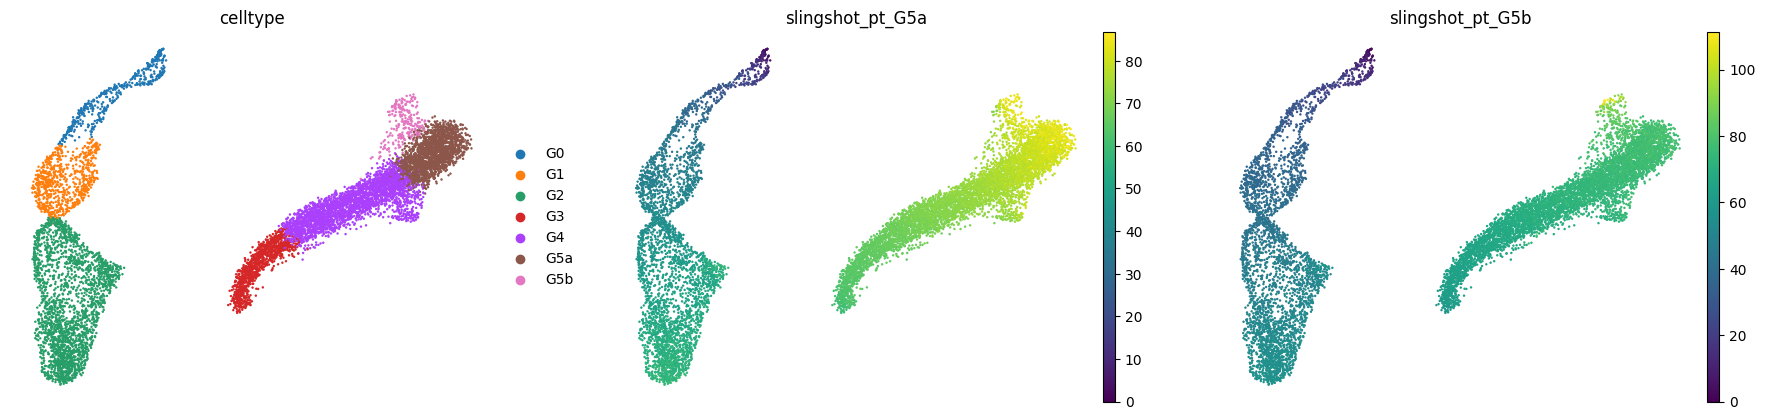

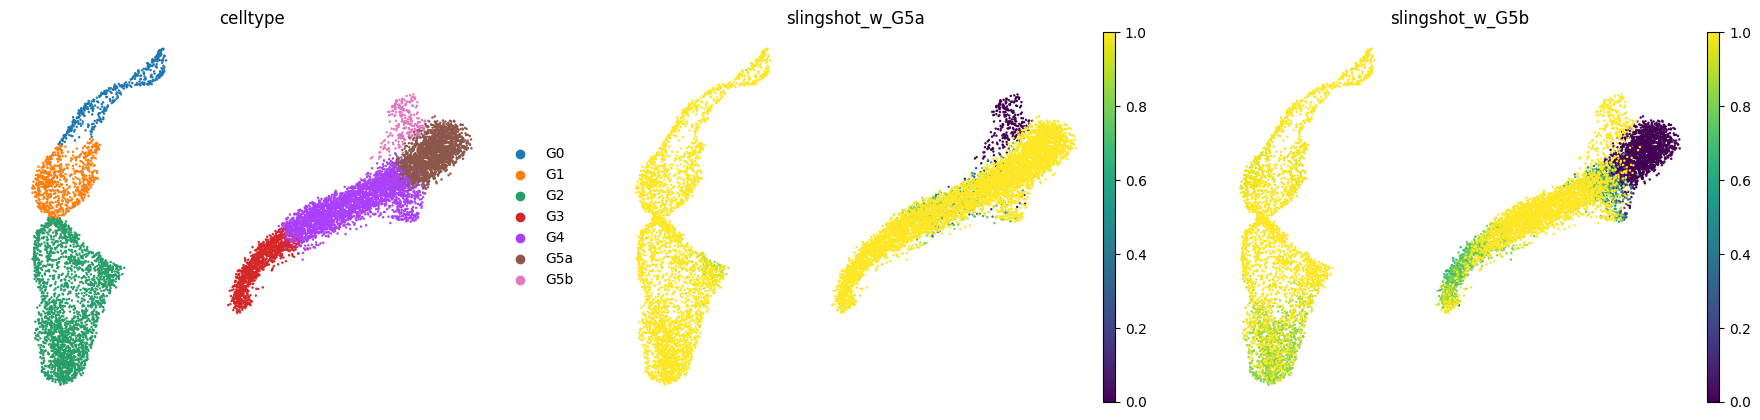

In [ ]:
## Visualize both lineages
sc.pl.umap(
    ad_sling,
    color=["celltype", "slingshot_pt_G5a", "slingshot_pt_G5b"],
    cmap="viridis",
    frameon=False,
    ncols=3,
)

# E os weights:
sc.pl.umap(
    ad_sling,
    color=["celltype", "slingshot_w_G5a", "slingshot_w_G5b"],
    cmap="viridis",
    frameon=False,
    ncols=3,
)

Esse segundo gráfico é particularmente útil agora porque mostra onde as células começam a se comprometer mais fortemente com cada lineage.

---

# tradeSeq on Slingshot

Aqui está a principal mudança em relação ao que estávamos fazendo.

Antes:

```text
DPT
→ 1 pseudotime
→ cellWeights = 1
```

Agora:

```text
Slingshot
→ pseudotime matrix:

cell × [G5a lineage, G5b lineage]

+

weight matrix:

cell × [G5a lineage, G5b lineage]
```

Essas são justamente as estruturas usadas pelo tradeSeq para múltiplas lineages [Van den Berge, 2020]. O trabalho encontrou o melhor desempenho geral com **tradeSeq downstream of Slingshot** nos benchmarks avaliados. 

## Condition-dependent gene dynamics along Slingshot lineages

The two-lineage Slingshot trajectory is now used as input for tradeSeq.

Unlike the previous single-lineage DPT model, both Slingshot-derived quantities are retained:

- lineage-specific pseudotimes;
- lineage-assignment weights.

tradeSeq models raw gene counts using negative-binomial generalized additive models (NB-GAMs), allowing expression to vary smoothly with pseudotime along each lineage [Van den Berge, 2020].

The multi-condition extension described by condiments additionally fits condition-specific smoothers, allowing WT and KO expression dynamics to be compared along corresponding lineages [Roux de Bézieux, 2024].

Therefore, for each gene the model can represent:

```text
             G5a lineage              G5b lineage

WT        smooth_WT_G5a            smooth_WT_G5b
KO        smooth_KO_G5a            smooth_KO_G5b
````

`conditionTest()` evaluates whether the fitted expression patterns differ between conditions across the mapped lineages [Roux de Bézieux, 2024].

The statistical test should be interpreted as evidence of condition-dependent expression dynamics rather than as a direct measure of biological effect magnitude.

````

---

# 5. Multi-lineage tradeSeq function

Aqui **uma nova função é realmente necessária**, porque a `RunTradeSeqConditionDynamics()` que você já tem foi escrita para:

```text
1 pseudotime
+
1 lineage
+
weights = 1
````

Agora temos uma matriz com duas lineages.


In [ ]:
def RunTradeSeqConditionDynamicsSlingshot(
    adata,
    slingshot_result,
    counts_layer,
    condition_col="condition",
    condition_order=("WT", "KO"),
    min_cells=20,
    nknots=6,
    n_cpus=1,
    seed=42,
):
    """
    Fit condition-specific tradeSeq NB-GAMs using Slingshot pseudotimes and weights.

    adata : AnnData --> Cells used to fit the Slingshot trajectory.
    slingshot_result : dict --> Output from RunSlingshotTrajectory.
    counts_layer : str --> Layer containing raw counts.
    condition_col : str --> Column containing experimental conditions.
    condition_order : tuple[str] --> Ordered condition levels.
    min_cells : int --> Minimum number of cells detecting a gene.
    nknots : int --> Number of knots used by tradeSeq.
    n_cpus : int --> Number of CPUs used by tradeSeq.
    seed : int --> Random seed.

    Returns
    -------
    dict --> conditionTest results, fitted model, genes, pseudotimes, weights and lineages.
    """
    import numpy as np
    import pandas as pd
    from scipy import sparse
    from rpy2 import robjects as ro
    from rpy2.robjects import numpy2ri, pandas2ri
    from rpy2.robjects.conversion import localconverter

    if counts_layer not in adata.layers:
        raise KeyError(f"Layer '{counts_layer}' not found in adata.layers.")

    if condition_col not in adata.obs:
        raise KeyError(f"Column '{condition_col}' not found in adata.obs.")

    if "model" not in slingshot_result or "lineages" not in slingshot_result:
        raise KeyError("slingshot_result must contain 'model' and 'lineages'.")

    # ------------------------------------------------------------
    # 1. Extract the official Slingshot inputs required by tradeSeq
    # ------------------------------------------------------------
    ro.globalenv["sling_model_trade"] = slingshot_result["model"]

    ro.r("""
        suppressPackageStartupMessages(library(slingshot))

        sling_pt_trade <- slingPseudotime(sling_model_trade, na=FALSE)
        sling_w_trade <- slingCurveWeights(sling_model_trade)
    """)

    with localconverter(ro.default_converter + numpy2ri.converter):
        pt_array = np.asarray(ro.conversion.rpy2py(ro.globalenv["sling_pt_trade"]))
        w_array = np.asarray(ro.conversion.rpy2py(ro.globalenv["sling_w_trade"]))

    sling_cells = [str(x) for x in ro.r("rownames(sling_pt_trade)")]
    lineage_names = [f"Lineage_{x.split(' -> ')[-1]}" for x in slingshot_result["lineages"]]

    if pt_array.shape != w_array.shape:
        raise ValueError(f"Pseudotime and weight matrices have different shapes: {pt_array.shape} vs {w_array.shape}.")

    if pt_array.shape[1] != len(lineage_names):
        raise ValueError("Number of Slingshot lineages does not match pseudotime matrix columns.")

    if len(sling_cells) != pt_array.shape[0]:
        raise ValueError("Could not recover Slingshot cell names correctly.")

    pseudotime = pd.DataFrame(pt_array, index=sling_cells, columns=lineage_names)
    weights = pd.DataFrame(w_array, index=sling_cells, columns=lineage_names)

    # ------------------------------------------------------------
    # 2. Match Slingshot cells to AnnData exactly
    # ------------------------------------------------------------
    cells = adata.obs_names.astype(str)

    missing = cells.difference(pseudotime.index)
    extra = pseudotime.index.difference(cells)

    if len(missing) > 0 or len(extra) > 0:
        raise ValueError(
            f"Slingshot and AnnData cells do not match. "
            f"Missing from Slingshot: {len(missing)}; "
            f"extra in Slingshot: {len(extra)}."
        )

    pseudotime = pseudotime.reindex(cells)
    weights = weights.reindex(cells)

    if pseudotime.isna().any().any():
        raise ValueError("tradeSeq pseudotime matrix contains NA values.")

    if weights.isna().any().any():
        raise ValueError("Slingshot weight matrix contains NA values.")

    if not np.isfinite(pseudotime.to_numpy()).all():
        raise ValueError("tradeSeq pseudotime matrix contains non-finite values.")

    if not np.isfinite(weights.to_numpy()).all():
        raise ValueError("Slingshot weight matrix contains non-finite values.")

    if (weights.sum(axis=1) <= 0).any():
        raise ValueError("At least one cell has no positive Slingshot lineage weight.")

    # ------------------------------------------------------------
    # 3. Prepare raw counts
    # ------------------------------------------------------------
    X = adata.layers[counts_layer]

    # CUSTOM: remove very sparsely detected genes
    if sparse.issparse(X):
        detected = np.asarray((X > 0).sum(axis=0)).ravel()
    else:
        detected = (np.asarray(X) > 0).sum(axis=0)

    keep = detected >= min_cells
    genes = adata.var_names[keep].astype(str)
    X = X[:, keep]

    if not sparse.issparse(X):
        X = sparse.csr_matrix(X)

    X = X.T.tocoo()

    # ------------------------------------------------------------
    # 4. Transfer genes x cells sparse count matrix to R
    # ------------------------------------------------------------
    ro.globalenv["i_idx"] = ro.IntVector((X.row + 1).astype(int))
    ro.globalenv["j_idx"] = ro.IntVector((X.col + 1).astype(int))
    ro.globalenv["x_val"] = ro.FloatVector(X.data.astype(float))
    ro.globalenv["n_genes"] = int(X.shape[0])
    ro.globalenv["n_cells"] = int(X.shape[1])
    ro.globalenv["gene_names"] = ro.StrVector(genes.tolist())
    ro.globalenv["cell_names"] = ro.StrVector(cells.tolist())

    with localconverter(ro.default_converter + numpy2ri.converter):
        ro.globalenv["pseudotime_mat"] = ro.conversion.py2rpy(pseudotime.to_numpy(dtype=float))
        ro.globalenv["cell_weights"] = ro.conversion.py2rpy(weights.to_numpy(dtype=float))

    conditions = adata.obs.loc[cells, condition_col].astype(str)

    unknown_conditions = set(conditions.unique()) - set(condition_order)
    if unknown_conditions:
        raise ValueError(f"Unexpected conditions found: {unknown_conditions}")

    if any(level not in conditions.values for level in condition_order):
        raise ValueError(f"Not all condition levels are present: {condition_order}")

    ro.globalenv["condition_vec"] = ro.StrVector(conditions.tolist())
    ro.globalenv["condition_levels"] = ro.StrVector(list(condition_order))
    ro.globalenv["nknots_run"] = int(nknots)
    ro.globalenv["n_cpus_run"] = int(n_cpus)
    ro.globalenv["seed_run"] = int(seed)

    # ------------------------------------------------------------
    # 5. Fit tradeSeq
    # ------------------------------------------------------------
    ro.r("""
        suppressPackageStartupMessages({
            library(Matrix)
            library(tradeSeq)
        })

        counts_mat <- sparseMatrix(
            i=i_idx,
            j=j_idx,
            x=x_val,
            dims=c(n_genes, n_cells)
        )

        rownames(counts_mat) <- gene_names
        colnames(counts_mat) <- cell_names

        rownames(pseudotime_mat) <- cell_names
        rownames(cell_weights) <- cell_names

        conditions <- factor(condition_vec, levels=condition_levels)

        set.seed(seed_run)

        if (n_cpus_run > 1) {

            suppressPackageStartupMessages(library(BiocParallel))

            bp <- MulticoreParam(workers=n_cpus_run)

            trade_model <- fitGAM(
                counts=counts_mat,
                pseudotime=pseudotime_mat,
                cellWeights=cell_weights,
                conditions=conditions,
                nknots=nknots_run,
                verbose=FALSE,
                parallel=TRUE,
                BPPARAM=bp
            )

        } else {

            trade_model <- fitGAM(
                counts=counts_mat,
                pseudotime=pseudotime_mat,
                cellWeights=cell_weights,
                conditions=conditions,
                nknots=nknots_run,
                verbose=FALSE,
                parallel=FALSE
            )
        }

        condition_res <- as.data.frame(
            conditionTest(
                trade_model,
                global=TRUE,
                pairwise=FALSE,
                l2fc=0
            )
        )

        condition_res$gene <- rownames(condition_res)
        condition_res$padj <- p.adjust(condition_res$pvalue, method="BH")
    """)

    with localconverter(ro.default_converter + pandas2ri.converter):
        results = ro.conversion.rpy2py(ro.globalenv["condition_res"])

    results = pd.DataFrame(results)

    results = results.sort_values(
        ["padj", "pvalue", "waldStat"],
        ascending=[True, True, False],
        na_position="last",
    ).reset_index(drop=True)

    return {
        "results": results,
        "model": ro.globalenv["trade_model"],
        "genes": genes.tolist(),
        "pseudotime": pseudotime,
        "weights": weights,
        "lineages": slingshot_result["lineages"],
    }


def RunTradeSeqConditionTest(trade_result, l2fc=0.0):
    """
    Re-run conditionTest on an already fitted tradeSeq model.

    trade_result : dict --> Output from a tradeSeq fitting function.
    l2fc : float --> Effect-size threshold supplied to conditionTest.

    Returns
    -------
    DataFrame --> conditionTest results with BH-adjusted p-values.
    """
    import pandas as pd
    from rpy2 import robjects as ro
    from rpy2.robjects import pandas2ri
    from rpy2.robjects.conversion import localconverter

    ro.globalenv["trade_model_test"] = trade_result["model"]
    ro.globalenv["l2fc_run"] = float(l2fc)

    ro.r("""
        suppressPackageStartupMessages(library(tradeSeq))

        condition_res_test <- as.data.frame(
            conditionTest(
                trade_model_test,
                global=TRUE,
                pairwise=FALSE,
                l2fc=l2fc_run
            )
        )

        condition_res_test$gene <- rownames(condition_res_test)
        condition_res_test$padj <- p.adjust(
            condition_res_test$pvalue,
            method="BH"
        )
    """)

    with localconverter(ro.default_converter + pandas2ri.converter):
        results = ro.conversion.rpy2py(ro.globalenv["condition_res_test"])

    results = pd.DataFrame(results)

    return results.sort_values(
        ["padj", "pvalue", "waldStat"],
        ascending=[True, True, False],
        na_position="last",
    ).reset_index(drop=True)

In [ ]:
# trade_slingshot = RunTradeSeqConditionDynamicsSlingshot(
#     adata=ad_sling,
#     slingshot_result=slingshot,
#     counts_layer="QC_filtered",
#     condition_col="condition",
#     condition_order=("WT", "KO"),
#     min_cells=20,
#     nknots=6,
#     n_cpus=1,
#     seed=42,
# )

# condition_slingshot = trade_slingshot["results"]

# display(condition_slingshot.head(10))

In [ ]:
# print(trade_slingshot["lineages"])

# print("Pseudotime shape:", trade_slingshot["pseudotime"].shape)
# print("Weights shape:", trade_slingshot["weights"].shape)

# print("Pseudotime NAs:", trade_slingshot["pseudotime"].isna().sum().to_dict())
# print("Weights NAs:", trade_slingshot["weights"].isna().sum().to_dict())

# print(
#     "Weight range:",
#     trade_slingshot["weights"].to_numpy().min(),
#     trade_slingshot["weights"].to_numpy().max(),
# )

# display(trade_slingshot["pseudotime"].describe())
# display(trade_slingshot["weights"].describe())

> ESSE DE CIMA TRAVOU E NÃO RODOU

In [20]:
def RunTradeSeqConditionDynamicsSlingshotChunked(
    adata,
    slingshot_result,
    counts_layer,
    condition_col="condition",
    condition_order=("WT", "KO"),
    min_cells=20,
    min_pct_cells=None,
    force_genes=(),
    nknots=6,
    chunk_size=250,
    fc_threshold=1.5,
    seed=42,
):
    """
    Fit condition-specific tradeSeq NB-GAMs in memory-efficient gene chunks.

    adata : AnnData --> Cells used for the Slingshot trajectory.
    slingshot_result : dict --> Output from RunSlingshotTrajectory.
    counts_layer : str --> Layer containing raw counts.
    condition_col : str --> Column containing experimental conditions.
    condition_order : tuple[str] --> Ordered condition levels.
    min_cells : int --> Minimum number of cells detecting a gene.
    min_pct_cells : float | None --> Optional minimum fraction of cells detecting a gene.
    force_genes : tuple[str] --> Genes retained regardless of the expression filter.
    nknots : int --> Number of knots used by tradeSeq.
    chunk_size : int --> Number of gene-specific GAMs fitted per chunk.
    fc_threshold : float --> Fold-change threshold used in the second conditionTest.
    seed : int --> Random seed used by fitGAM.

    Returns
    -------
    dict --> Standard and effect-size conditionTest results plus Slingshot inputs.
    """
    import gc
    import numpy as np
    import pandas as pd
    from scipy import sparse
    from rpy2 import robjects as ro
    from rpy2.robjects import numpy2ri, pandas2ri
    from rpy2.robjects.conversion import localconverter

    # ------------------------------------------------------------
    # 1. Basic checks
    # ------------------------------------------------------------
    if counts_layer not in adata.layers:
        raise KeyError(f"Layer '{counts_layer}' not found in adata.layers.")

    if condition_col not in adata.obs:
        raise KeyError(f"Column '{condition_col}' not found in adata.obs.")

    if "model" not in slingshot_result or "lineages" not in slingshot_result:
        raise KeyError("slingshot_result must contain 'model' and 'lineages'.")

    cells = adata.obs_names.astype(str)

    # ------------------------------------------------------------
    # 2. Extract official Slingshot inputs required by tradeSeq
    # ------------------------------------------------------------
    ro.globalenv["sling_model_trade"] = slingshot_result["model"]

    ro.r("""
        suppressPackageStartupMessages(library(slingshot))

        sling_pt_trade <- slingPseudotime(sling_model_trade, na=FALSE)
        sling_w_trade <- slingCurveWeights(sling_model_trade)
    """)

    with localconverter(ro.default_converter + numpy2ri.converter):
        pt_array = np.asarray(ro.conversion.rpy2py(ro.globalenv["sling_pt_trade"]))
        w_array = np.asarray(ro.conversion.rpy2py(ro.globalenv["sling_w_trade"]))

    sling_cells = pd.Index([str(x) for x in ro.r("rownames(sling_pt_trade)")])
    lineage_names = [f"Lineage_{x.split(' -> ')[-1]}" for x in slingshot_result["lineages"]]

    pseudotime = pd.DataFrame(pt_array, index=sling_cells, columns=lineage_names).reindex(cells)
    weights = pd.DataFrame(w_array, index=sling_cells, columns=lineage_names).reindex(cells)

    if pseudotime.isna().any().any():
        raise ValueError("Slingshot pseudotime contains NA values.")

    if weights.isna().any().any():
        raise ValueError("Slingshot lineage weights contain NA values.")

    if not np.isfinite(pseudotime.to_numpy()).all():
        raise ValueError("Slingshot pseudotime contains non-finite values.")

    if not np.isfinite(weights.to_numpy()).all():
        raise ValueError("Slingshot lineage weights contain non-finite values.")

    if (weights.sum(axis=1) <= 0).any():
        raise ValueError("At least one cell has no positive lineage weight.")

    # ------------------------------------------------------------
    # 3. Filter very sparse genes
    # ------------------------------------------------------------
    X_all = adata.layers[counts_layer]

    if sparse.issparse(X_all):
        detected = np.asarray((X_all > 0).sum(axis=0)).ravel()
    else:
        detected = (np.asarray(X_all) > 0).sum(axis=0)

    min_detected = min_cells

    if min_pct_cells is not None:
        min_detected = max(min_cells, int(np.ceil(min_pct_cells * adata.n_obs)))

    keep = detected >= min_detected

    for gene in force_genes:
        if gene in adata.var_names:
            keep[adata.var_names.get_loc(gene)] = True

    gene_idx = np.flatnonzero(keep)
    genes = adata.var_names[gene_idx].astype(str)

    print(f"Cells: {adata.n_obs}")
    print(f"Genes retained: {len(genes)}")
    print(f"Minimum detected cells: {min_detected}")
    print(f"Chunk size: {chunk_size}")
    print(f"Chunks: {int(np.ceil(len(genes) / chunk_size))}")

    # ------------------------------------------------------------
    # 4. Transfer the COMPLETE filtered count matrix once
    # ------------------------------------------------------------
    X = X_all[:, gene_idx]

    if not sparse.issparse(X):
        X = sparse.csr_matrix(X)

    X = X.T.tocoo()  # genes x cells

    ro.globalenv["i_full"] = ro.IntVector((X.row + 1).astype(int))
    ro.globalenv["j_full"] = ro.IntVector((X.col + 1).astype(int))
    ro.globalenv["x_full"] = ro.FloatVector(X.data.astype(float))
    ro.globalenv["n_genes"] = int(X.shape[0])
    ro.globalenv["n_cells"] = int(X.shape[1])
    ro.globalenv["gene_names"] = ro.StrVector(genes.tolist())
    ro.globalenv["cell_names"] = ro.StrVector(cells.tolist())

    with localconverter(ro.default_converter + numpy2ri.converter):
        ro.globalenv["pseudotime_mat"] = ro.conversion.py2rpy(pseudotime.to_numpy(dtype=float))
        ro.globalenv["cell_weights"] = ro.conversion.py2rpy(weights.to_numpy(dtype=float))

    conditions = adata.obs.loc[cells, condition_col].astype(str)

    unknown = set(conditions.unique()) - set(condition_order)
    if unknown:
        raise ValueError(f"Unexpected conditions found: {unknown}")

    if any(level not in conditions.values for level in condition_order):
        raise ValueError(f"Not all condition levels are present: {condition_order}")

    ro.globalenv["condition_vec"] = ro.StrVector(conditions.tolist())
    ro.globalenv["condition_levels"] = ro.StrVector(list(condition_order))
    ro.globalenv["nknots_run"] = int(nknots)
    ro.globalenv["seed_run"] = int(seed)
    ro.globalenv["l2fc_run"] = float(np.log2(fc_threshold))

    ro.r("""
        suppressPackageStartupMessages({
            library(Matrix)
            library(tradeSeq)
            library(SummarizedExperiment)
        })

        counts_full <- sparseMatrix(
            i=i_full,
            j=j_full,
            x=x_full,
            dims=c(n_genes, n_cells)
        )

        rownames(counts_full) <- gene_names
        colnames(counts_full) <- cell_names

        rownames(pseudotime_mat) <- cell_names
        rownames(cell_weights) <- cell_names

        conditions <- factor(condition_vec, levels=condition_levels)

        # Release transfer vectors; counts_full is now the persistent sparse matrix
        rm(i_full, j_full, x_full)
        gc()
    """)

    del X
    gc.collect()

    results_standard = []
    results_fc = []

    # ------------------------------------------------------------
    # 5. Fit only the requested genes from each chunk
    #    while counts_full remains identical for every fit
    # ------------------------------------------------------------
    n_chunks = int(np.ceil(len(genes) / chunk_size))

    for chunk_number, start in enumerate(range(0, len(genes), chunk_size), 1):

        stop = min(start + chunk_size, len(genes))

        # fitGAM uses R row indices
        genes_run = np.arange(start + 1, stop + 1, dtype=int)

        ro.globalenv["genes_run"] = ro.IntVector(genes_run.tolist())

        print(f"Chunk {chunk_number}/{n_chunks}: genes {start + 1}-{stop}")

        ro.r("""
            # fitGAM is stochastic when lineage weights are soft.
            # Resetting the same seed makes each chunk reproducible.
            set.seed(seed_run)

            trade_model_chunk <- fitGAM(
                counts=counts_full,
                genes=genes_run,
                pseudotime=pseudotime_mat,
                cellWeights=cell_weights,
                conditions=conditions,
                nknots=nknots_run,
                verbose=FALSE,
                parallel=FALSE
            )

            condition_chunk <- as.data.frame(
                conditionTest(
                    trade_model_chunk,
                    global=TRUE,
                    pairwise=FALSE,
                    l2fc=0
                )
            )

            condition_fc_chunk <- as.data.frame(
                conditionTest(
                    trade_model_chunk,
                    global=TRUE,
                    pairwise=FALSE,
                    l2fc=l2fc_run
                )
            )

            condition_chunk$gene <- rownames(condition_chunk)
            condition_fc_chunk$gene <- rownames(condition_fc_chunk)

            conv_chunk <- SummarizedExperiment::rowData(
                trade_model_chunk
            )$tradeSeq$converged

            names(conv_chunk) <- rownames(trade_model_chunk)

            condition_chunk$converged <- conv_chunk[
                match(condition_chunk$gene, names(conv_chunk))
            ]

            condition_fc_chunk$converged <- conv_chunk[
                match(condition_fc_chunk$gene, names(conv_chunk))
            ]
        """)

        with localconverter(ro.default_converter + pandas2ri.converter):
            res = pd.DataFrame(ro.conversion.rpy2py(ro.globalenv["condition_chunk"]))
            res_fc = pd.DataFrame(ro.conversion.rpy2py(ro.globalenv["condition_fc_chunk"]))

        results_standard.append(res)
        results_fc.append(res_fc)

        # Remove only chunk-specific fitted objects
        ro.r("""
            rm(
                trade_model_chunk,
                condition_chunk,
                condition_fc_chunk,
                conv_chunk,
                genes_run
            )
            gc()
        """)

        del res, res_fc
        gc.collect()

    # ------------------------------------------------------------
    # 6. Combine all genes
    # ------------------------------------------------------------
    results = pd.concat(results_standard, ignore_index=True)
    results_fc = pd.concat(results_fc, ignore_index=True)

    # ------------------------------------------------------------
    # 7. Apply BH once across ALL tested genes
    # ------------------------------------------------------------
    def AddBH(df):
        pvalues = [
            ro.NA_Real if not np.isfinite(x) else float(x)
            for x in df["pvalue"].to_numpy(dtype=float)
        ]

        ro.globalenv["pvalues_tmp"] = ro.FloatVector(pvalues)
        padj = np.asarray(ro.r('p.adjust(pvalues_tmp, method="BH")'), dtype=float)

        out = df.copy()
        out["padj"] = padj
        return out

    results = AddBH(results)
    results_fc = AddBH(results_fc)

    results = results.sort_values(
        ["padj", "pvalue", "waldStat"],
        ascending=[True, True, False],
        na_position="last",
    ).reset_index(drop=True)

    results_fc = results_fc.sort_values(
        ["padj", "pvalue", "waldStat"],
        ascending=[True, True, False],
        na_position="last",
    ).reset_index(drop=True)

    # ------------------------------------------------------------
    # 8. Clean large R objects
    # ------------------------------------------------------------
    ro.r("""
        rm(counts_full)
        gc()
    """)

    gc.collect()

    return {
        "results": results,
        "results_fc": results_fc,
        "genes": genes.tolist(),
        "pseudotime": pseudotime,
        "weights": weights,
        "lineages": slingshot_result["lineages"],
        "fc_threshold": fc_threshold,
        "nknots": nknots,
        "chunk_size": chunk_size,
    }

In [21]:
trade_slingshot_final = RunTradeSeqConditionDynamicsSlingshotChunked(
    adata=ad_sling,
    slingshot_result=slingshot,
    counts_layer="QC_filtered",
    condition_col="condition",
    condition_order=("WT", "KO"),
    min_cells=20,
    min_pct_cells=None,
    force_genes=("Ffar2",),
    nknots=6,
    chunk_size=250,
    fc_threshold=1.5,
    seed=42,
)

Cells: 9755
Genes retained: 16552
Minimum detected cells: 20
Chunk size: 250
Chunks: 67
Chunk 1/67: genes 1-250


R callback write-console: Fitting lineages with multiple conditions. This method has been tested on a couple of datasets, but is still in an experimental phase.
  
R callback write-console: Além disso:   
R callback write-console: Mensagen de aviso:
  
R callback write-console: In asMethod(object) :  
R callback write-console: 
   
R callback write-console:  sparse->dense coercion: allocating vector of size 1.2 GiB
  


Chunk 2/67: genes 251-500


R callback write-console: Fitting lineages with multiple conditions. This method has been tested on a couple of datasets, but is still in an experimental phase.
  
R callback write-console: Além disso:   
R callback write-console: Mensagen de aviso:
  
R callback write-console: In asMethod(object) :  
R callback write-console: 
   
R callback write-console:  sparse->dense coercion: allocating vector of size 1.2 GiB
  


Chunk 3/67: genes 501-750


...

R callback write-console: Fitting lineages with multiple conditions. This method has been tested on a couple of datasets, but is still in an experimental phase.
  
R callback write-console: Além disso:   
R callback write-console: Mensagen de aviso:
  
R callback write-console: In asMethod(object) :  
R callback write-console: 
   
R callback write-console:  sparse->dense coercion: allocating vector of size 1.2 GiB
  


Chunk 66/67: genes 16251-16500


R callback write-console: Fitting lineages with multiple conditions. This method has been tested on a couple of datasets, but is still in an experimental phase.
  
R callback write-console: Além disso:   
R callback write-console: Mensagen de aviso:
  
R callback write-console: In asMethod(object) :  
R callback write-console: 
   
R callback write-console:  sparse->dense coercion: allocating vector of size 1.2 GiB
  


Chunk 67/67: genes 16501-16552


R callback write-console: Fitting lineages with multiple conditions. This method has been tested on a couple of datasets, but is still in an experimental phase.
  
R callback write-console: Além disso:   
R callback write-console: Mensagen de aviso:
  
R callback write-console: In asMethod(object) :  
R callback write-console: 
   
R callback write-console:  sparse->dense coercion: allocating vector of size 1.2 GiB
  


In [22]:
condition_slingshot = trade_slingshot_final["results"]
condition_slingshot_fc15 = trade_slingshot_final["results_fc"]

print("Genes tested:", len(condition_slingshot))
print("NA standard:", condition_slingshot[["waldStat", "pvalue", "padj"]].isna().sum().to_dict())
print("NA fc15:", condition_slingshot_fc15[["waldStat", "pvalue", "padj"]].isna().sum().to_dict())

print("Non-converged:", (condition_slingshot["converged"] == False).sum())

display(condition_slingshot.head(20))
display(condition_slingshot_fc15.head(20))
display(condition_slingshot[condition_slingshot["gene"] == "Ffar2"])

Genes tested: 16552
NA standard: {'waldStat': 7, 'pvalue': 7, 'padj': 7}
NA fc15: {'waldStat': 7, 'pvalue': 7, 'padj': 7}
Non-converged: 2


,waldStat,df,pvalue,gene,converged,padj
0,494.095096,4.0,0.000000e+00,Camp,True,0.000000e+00
1,457.445280,4.0,0.000000e+00,Ngp,True,0.000000e+00
2,328.615042,8.0,0.000000e+00,Fosb,True,0.000000e+00
3,218.731814,4.0,0.000000e+00,Ltf,True,0.000000e+00
4,183.787380,8.0,0.000000e+00,Blvrb,True,0.000000e+00
5,151.515082,4.0,0.000000e+00,Wfdc21,True,0.000000e+00
6,151.242136,4.0,0.000000e+00,Cd177,True,0.000000e+00
7,146.202524,4.0,0.000000e+00,Lcn2,True,0.000000e+00
8,130.388378,8.0,0.000000e+00,Gramd1a,True,0.000000e+00
9,125.096416,4.0,0.000000e+00,Chil1,True,0.000000e+00


,waldStat,df,pvalue,gene,converged,padj
0,472.799876,4.0,0.000000e+00,Camp,True,0.000000e+00
1,432.787579,4.0,0.000000e+00,Ngp,True,0.000000e+00
2,202.352224,4.0,0.000000e+00,Ltf,True,0.000000e+00
3,140.795825,4.0,0.000000e+00,Cd177,True,0.000000e+00
4,122.970301,4.0,0.000000e+00,Wfdc21,True,0.000000e+00
5,121.869506,4.0,0.000000e+00,Lcn2,True,0.000000e+00
6,116.177803,4.0,0.000000e+00,Chil1,True,0.000000e+00
7,103.867837,8.0,0.000000e+00,Blvrb,True,0.000000e+00
8,84.100954,4.0,0.000000e+00,Gm34680,True,0.000000e+00
9,71.465753,4.0,1.110223e-14,Il1r2,True,1.836864e-11


,waldStat,df,pvalue,gene,converged,padj
791,4.83166,2.0,0.089293,Ffar2,True,1.0


In [25]:
condition_slingshot = trade_slingshot_final["results"]
condition_slingshot_fc15 = trade_slingshot_final["results_fc"]

candidates_slingshot = condition_slingshot.query("padj < 0.05").copy()
candidates_slingshot_fc15 = condition_slingshot_fc15.query("padj < 0.05").copy()

print(f"Genes tested: {len(condition_slingshot)}")
print(f"Standard candidates: {len(candidates_slingshot)}")
print(f"1.5-fold candidates: {len(candidates_slingshot_fc15)}")

print("\nNA standard:")
print(condition_slingshot[["waldStat", "pvalue", "padj"]].isna().sum())

print("\nNA 1.5-fold:")
print(condition_slingshot_fc15[["waldStat", "pvalue", "padj"]].isna().sum())

print("\nNon-converged:")
print((condition_slingshot["converged"] == False).sum())

print("\nTop standard:")
display(condition_slingshot.head(20))

print("\nTop 1.5-fold:")
display(condition_slingshot_fc15.head(20))

print("\nFfar2:")
display(condition_slingshot[condition_slingshot["gene"] == "Ffar2"])

print("\nFfar2 — 1.5-fold:")
display(condition_slingshot_fc15[condition_slingshot_fc15["gene"] == "Ffar2"])

Genes tested: 16552
Standard candidates: 56
1.5-fold candidates: 30

NA standard:
waldStat    7
pvalue      7
padj        7
dtype: int64

NA 1.5-fold:
waldStat    7
pvalue      7
padj        7
dtype: int64

Non-converged:
2

Top standard:


,waldStat,df,pvalue,gene,converged,padj
0,494.095096,4.0,0.000000e+00,Camp,True,0.000000e+00
1,457.445280,4.0,0.000000e+00,Ngp,True,0.000000e+00
2,328.615042,8.0,0.000000e+00,Fosb,True,0.000000e+00
3,218.731814,4.0,0.000000e+00,Ltf,True,0.000000e+00
4,183.787380,8.0,0.000000e+00,Blvrb,True,0.000000e+00
5,151.515082,4.0,0.000000e+00,Wfdc21,True,0.000000e+00
6,151.242136,4.0,0.000000e+00,Cd177,True,0.000000e+00
7,146.202524,4.0,0.000000e+00,Lcn2,True,0.000000e+00
8,130.388378,8.0,0.000000e+00,Gramd1a,True,0.000000e+00
9,125.096416,4.0,0.000000e+00,Chil1,True,0.000000e+00



Top 1.5-fold:


,waldStat,df,pvalue,gene,converged,padj
0,472.799876,4.0,0.000000e+00,Camp,True,0.000000e+00
1,432.787579,4.0,0.000000e+00,Ngp,True,0.000000e+00
2,202.352224,4.0,0.000000e+00,Ltf,True,0.000000e+00
3,140.795825,4.0,0.000000e+00,Cd177,True,0.000000e+00
4,122.970301,4.0,0.000000e+00,Wfdc21,True,0.000000e+00
5,121.869506,4.0,0.000000e+00,Lcn2,True,0.000000e+00
6,116.177803,4.0,0.000000e+00,Chil1,True,0.000000e+00
7,103.867837,8.0,0.000000e+00,Blvrb,True,0.000000e+00
8,84.100954,4.0,0.000000e+00,Gm34680,True,0.000000e+00
9,71.465753,4.0,1.110223e-14,Il1r2,True,1.836864e-11



Ffar2:


,waldStat,df,pvalue,gene,converged,padj
791,4.83166,2.0,0.089293,Ffar2,True,1.0



Ffar2 — 1.5-fold:


,waldStat,df,pvalue,gene,converged,padj
293,4.737968,2.0,0.093576,Ffar2,True,1.0


In [27]:
selected_genes = (
    condition_slingshot_fc15
    .query("padj < 0.05 and converged == True")
    ["gene"]
    .tolist()
)

if "Ffar2" not in selected_genes:
    selected_genes.append("Ffar2")

print(f"Genes selected: {len(selected_genes)}")
print(selected_genes)

Genes selected: 31
['Camp', 'Ngp', 'Ltf', 'Cd177', 'Wfdc21', 'Lcn2', 'Chil1', 'Blvrb', 'Gm34680', 'Il1r2', 'Lrg1', 'Olfml2b', 'Alox5', 'C5ar1', 'Itgb2l', 'Pglyrp1', 'Ptprt', 'Mmp25', 'Inhba', 'Ifnlr1', 'S100a9', 'Igkc', 'Cstdc4', 'Tnfsf13b', 'Fosb', 'Cdca8', 'Cd33', 'Mmp9', 'Klf4', 'Hba-a2', 'Ffar2']


In [28]:
def RunTradeSeqSelectedLineageTests(
    adata,
    trade_result,
    genes,
    counts_layer="QC_filtered",
    condition_col="condition",
    condition_order=("WT", "KO"),
    fc_threshold=1.5,
    seed=42,
):
    """
    Refit selected genes and test condition differences within each lineage.

    adata : AnnData --> Cells used in the trajectory analysis.
    trade_result : dict --> Final chunked tradeSeq result.
    genes : list[str] --> Genes selected for follow-up analysis.
    counts_layer : str --> Layer containing raw counts.
    condition_col : str --> Column containing experimental conditions.
    condition_order : tuple[str] --> Ordered condition levels.
    fc_threshold : float --> Fold-change threshold for the second conditionTest.
    seed : int --> Random seed.

    Returns
    -------
    dict --> Fitted model and global/lineage-specific conditionTest results.
    """
    import gc
    import numpy as np
    import pandas as pd
    from scipy import sparse
    from rpy2 import robjects as ro
    from rpy2.robjects import numpy2ri, pandas2ri
    from rpy2.robjects.conversion import localconverter

    cells = adata.obs_names.astype(str)

    # Use exactly the genes retained in the final genome-wide fit
    normalization_genes = pd.Index(trade_result["genes"])
    selected_genes = [g for g in genes if g in normalization_genes]

    if not selected_genes:
        raise ValueError("None of the selected genes are present in trade_result['genes'].")

    # Retrieve the exact pseudotimes and weights used in the final analysis
    pseudotime = trade_result["pseudotime"].reindex(cells)
    weights = trade_result["weights"].reindex(cells)

    if pseudotime.isna().any().any() or weights.isna().any().any():
        raise ValueError("Pseudotime or lineage weights contain NA values.")

    # Full filtered count matrix: same normalization context as final analysis
    norm_idx = adata.var_names.get_indexer(normalization_genes)

    if (norm_idx < 0).any():
        raise ValueError("Some normalization genes are missing from adata.var_names.")

    X = adata.layers[counts_layer][:, norm_idx]

    if not sparse.issparse(X):
        X = sparse.csr_matrix(X)

    X = X.T.tocoo()  # genes x cells

    selected_idx = normalization_genes.get_indexer(selected_genes) + 1  # R indexing

    # Transfer full sparse matrix
    ro.globalenv["i_full"] = ro.IntVector((X.row + 1).astype(int))
    ro.globalenv["j_full"] = ro.IntVector((X.col + 1).astype(int))
    ro.globalenv["x_full"] = ro.FloatVector(X.data.astype(float))
    ro.globalenv["n_genes"] = int(X.shape[0])
    ro.globalenv["n_cells"] = int(X.shape[1])
    ro.globalenv["gene_names"] = ro.StrVector(normalization_genes.tolist())
    ro.globalenv["cell_names"] = ro.StrVector(cells.tolist())
    ro.globalenv["genes_run"] = ro.IntVector(selected_idx.astype(int))

    with localconverter(ro.default_converter + numpy2ri.converter):
        ro.globalenv["pseudotime_mat"] = ro.conversion.py2rpy(
            pseudotime.to_numpy(dtype=float)
        )
        ro.globalenv["cell_weights"] = ro.conversion.py2rpy(
            weights.to_numpy(dtype=float)
        )

    conditions = adata.obs.loc[cells, condition_col].astype(str)

    ro.globalenv["condition_vec"] = ro.StrVector(conditions.tolist())
    ro.globalenv["condition_levels"] = ro.StrVector(list(condition_order))
    ro.globalenv["nknots_run"] = int(trade_result["nknots"])
    ro.globalenv["seed_run"] = int(seed)
    ro.globalenv["l2fc_run"] = float(np.log2(fc_threshold))

    ro.r("""
        suppressPackageStartupMessages({
            library(Matrix)
            library(tradeSeq)
            library(SummarizedExperiment)
        })

        counts_full_selected <- sparseMatrix(
            i=i_full,
            j=j_full,
            x=x_full,
            dims=c(n_genes, n_cells)
        )

        rownames(counts_full_selected) <- gene_names
        colnames(counts_full_selected) <- cell_names

        rownames(pseudotime_mat) <- cell_names
        rownames(cell_weights) <- cell_names

        conditions <- factor(condition_vec, levels=condition_levels)

        set.seed(seed_run)

        selected_model <- fitGAM(
            counts=counts_full_selected,
            genes=genes_run,
            pseudotime=pseudotime_mat,
            cellWeights=cell_weights,
            conditions=conditions,
            nknots=nknots_run,
            verbose=FALSE,
            parallel=FALSE
        )

        # Global + WT vs KO within each lineage
        lineage_standard <- as.data.frame(
            conditionTest(
                selected_model,
                global=TRUE,
                pairwise=FALSE,
                lineages=TRUE,
                l2fc=0
            )
        )

        lineage_fc <- as.data.frame(
            conditionTest(
                selected_model,
                global=TRUE,
                pairwise=FALSE,
                lineages=TRUE,
                l2fc=l2fc_run
            )
        )

        lineage_standard$gene <- rownames(lineage_standard)
        lineage_fc$gene <- rownames(lineage_fc)

        converged_selected <- rowData(selected_model)$tradeSeq$converged

        lineage_standard$converged <- converged_selected
        lineage_fc$converged <- converged_selected
    """)

    with localconverter(ro.default_converter + pandas2ri.converter):
        standard = pd.DataFrame(
            ro.conversion.rpy2py(ro.globalenv["lineage_standard"])
        )
        fc = pd.DataFrame(
            ro.conversion.rpy2py(ro.globalenv["lineage_fc"])
        )

    # Rename lineage1/lineage2 to G5a/G5b using the actual Slingshot order
    lineage_labels = [x.split(" -> ")[-1] for x in trade_result["lineages"]]

    def RenameLineages(df):
        rename = {}

        for i, label in enumerate(lineage_labels, 1):
            for metric in ["waldStat", "df", "pvalue"]:
                old = f"{metric}_lineage{i}"

                if old in df.columns:
                    rename[old] = f"{metric}_{label}"

        return df.rename(columns=rename)

    standard = RenameLineages(standard)
    fc = RenameLineages(fc)

    # BH only among these follow-up genes, separately for each lineage
    def AddFollowupBH(df):
        out = df.copy()

        for label in lineage_labels:
            pcol = f"pvalue_{label}"

            if pcol not in out.columns:
                continue

            values = [
                ro.NA_Real if not np.isfinite(x) else float(x)
                for x in out[pcol].to_numpy(dtype=float)
            ]

            ro.globalenv["p_tmp"] = ro.FloatVector(values)

            out[f"padj_followup_{label}"] = np.asarray(
                ro.r('p.adjust(p_tmp, method="BH")'),
                dtype=float,
            )

        return out

    standard = AddFollowupBH(standard)
    fc = AddFollowupBH(fc)

    ro.r("""
        rm(
            counts_full_selected,
            i_full,
            j_full,
            x_full,
            lineage_standard,
            lineage_fc,
            converged_selected
        )
        gc()
    """)

    del X
    gc.collect()

    return {
        "model": ro.globalenv["selected_model"],
        "results": standard.reset_index(drop=True),
        "results_fc": fc.reset_index(drop=True),
        "genes": selected_genes,
        "lineages": lineage_labels,
        "fc_threshold": fc_threshold,
    }

In [30]:
lineage_tests = RunTradeSeqSelectedLineageTests(
    adata=ad_sling,
    trade_result=trade_slingshot_final,
    genes=selected_genes,
    counts_layer="QC_filtered",
    condition_col="condition",
    condition_order=("WT", "KO"),
    fc_threshold=1.5,
    seed=42,
)

R callback write-console: Fitting lineages with multiple conditions. This method has been tested on a couple of datasets, but is still in an experimental phase.
  
R callback write-console: Além disso:   
R callback write-console: Mensagen de aviso:
  
R callback write-console: In asMethod(object) :  
R callback write-console: 
   
R callback write-console:  sparse->dense coercion: allocating vector of size 1.2 GiB
  


In [31]:
lineage_fc15 = lineage_tests["results_fc"]

display(
    lineage_fc15[
        [
            "gene",
            "waldStat",
            "pvalue",
            "pvalue_G5a",
            "padj_followup_G5a",
            "pvalue_G5b",
            "padj_followup_G5b",
        ]
    ].sort_values("pvalue")
)

,gene,waldStat,pvalue,pvalue_G5a,padj_followup_G5a,pvalue_G5b,padj_followup_G5b
0,Camp,472.799876,0.000000e+00,2.220446e-16,1.609823e-15,0.000000e+00,0.000000e+00
1,Ngp,432.787579,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
2,Ltf,202.352224,0.000000e+00,7.549517e-15,4.378720e-14,0.000000e+00,0.000000e+00
3,Cd177,140.795825,0.000000e+00,0.000000e+00,0.000000e+00,2.754451e-03,3.993954e-03
4,Wfdc21,122.970301,0.000000e+00,3.399769e-07,5.477406e-07,0.000000e+00,0.000000e+00
5,Lcn2,121.869506,0.000000e+00,3.122393e-07,5.326435e-07,0.000000e+00,0.000000e+00
6,Chil1,116.177803,0.000000e+00,0.000000e+00,0.000000e+00,6.335000e-03,8.748334e-03
7,Blvrb,103.867837,0.000000e+00,9.281464e-14,4.486041e-13,2.011764e-07,5.303742e-07
8,Gm34680,84.100954,0.000000e+00,9.332224e-10,2.706345e-09,5.857668e-10,1.698724e-09
9,Il1r2,71.465753,1.110223e-14,9.781065e-13,3.545636e-12,3.097731e-04,4.990789e-04


In [32]:
lineage_standard = lineage_tests["results"]

display(
    lineage_standard[
        [
            "gene",
            "waldStat",
            "pvalue",
            "pvalue_G5a",
            "padj_followup_G5a",
            "pvalue_G5b",
            "padj_followup_G5b",
        ]
    ].sort_values("pvalue")
)

,gene,waldStat,pvalue,pvalue_G5a,padj_followup_G5a,pvalue_G5b,padj_followup_G5b
0,Camp,494.095096,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
1,Ngp,457.445280,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
2,Ltf,218.731814,0.000000e+00,1.110223e-15,4.599495e-15,0.000000e+00,0.000000e+00
3,Cd177,151.242136,0.000000e+00,0.000000e+00,0.000000e+00,6.079878e-04,8.815823e-04
4,Wfdc21,151.515082,0.000000e+00,9.614792e-10,1.991636e-09,0.000000e+00,0.000000e+00
5,Lcn2,146.202524,0.000000e+00,3.904264e-09,7.548244e-09,0.000000e+00,0.000000e+00
6,Chil1,125.096416,0.000000e+00,0.000000e+00,0.000000e+00,1.051364e-03,1.451884e-03
7,Blvrb,183.787380,0.000000e+00,0.000000e+00,0.000000e+00,2.179368e-13,7.900208e-13
8,Gm34680,93.240352,0.000000e+00,1.074432e-10,2.596543e-10,5.271528e-11,1.175956e-10
16,Ptprt,90.207620,0.000000e+00,6.616929e-13,1.918909e-12,3.899354e-08,7.538752e-08


In [33]:
import numpy as np

lineage_candidates = lineage_fc15[
    lineage_fc15["gene"].isin(candidates_slingshot_fc15["gene"])
].copy()

sig_G5a = lineage_candidates["padj_followup_G5a"] < 0.05
sig_G5b = lineage_candidates["padj_followup_G5b"] < 0.05

lineage_candidates["lineage_effect"] = np.select(
    [
        sig_G5a & sig_G5b,
        sig_G5a & ~sig_G5b,
        ~sig_G5a & sig_G5b,
    ],
    [
        "G5a + G5b",
        "G5a only",
        "G5b only",
    ],
    default="Neither",
)

display(
    lineage_candidates[
        [
            "gene",
            "lineage_effect",
            "pvalue_G5a",
            "padj_followup_G5a",
            "pvalue_G5b",
            "padj_followup_G5b",
        ]
    ].sort_values(["lineage_effect", "gene"])
)

print(lineage_candidates["lineage_effect"].value_counts())

,gene,lineage_effect,pvalue_G5a,padj_followup_G5a,pvalue_G5b,padj_followup_G5b
12,Alox5,G5a + G5b,1.212968e-07,2.345071e-07,6.519453e-07,1.454339e-06
7,Blvrb,G5a + G5b,9.281464e-14,4.486041e-13,2.011764e-07,5.303742e-07
0,Camp,G5a + G5b,2.220446e-16,1.609823e-15,0.000000e+00,0.000000e+00
3,Cd177,G5a + G5b,0.000000e+00,0.000000e+00,2.754451e-03,3.993954e-03
26,Cd33,G5a + G5b,1.695490e-05,2.388884e-05,1.672506e-02,2.108811e-02
6,Chil1,G5a + G5b,0.000000e+00,0.000000e+00,6.335000e-03,8.748334e-03
24,Fosb,G5a + G5b,1.454983e-04,1.834544e-04,3.280229e-04,5.006666e-04
8,Gm34680,G5a + G5b,9.332224e-10,2.706345e-09,5.857668e-10,1.698724e-09
19,Ifnlr1,G5a + G5b,1.207458e-09,3.183298e-09,1.313068e-02,1.730862e-02
9,Il1r2,G5a + G5b,9.781065e-13,3.545636e-12,3.097731e-04,4.990789e-04


lineage_effect
G5a + G5b    20
G5a only      6
G5b only      3
Neither       1
Name: count, dtype: int64


In [34]:
def PrepareTradeSeqPlotCounts(adata, lineage_tests, counts_layer="QC_filtered"):
    """Transfer selected-gene counts to R for tradeSeq plotting."""
    import numpy as np
    from scipy import sparse
    from rpy2 import robjects as ro

    genes = lineage_tests["genes"]
    idx = adata.var_names.get_indexer(genes)

    X = adata.layers[counts_layer][:, idx]

    if not sparse.issparse(X):
        X = sparse.csr_matrix(X)

    X = X.T.tocoo()

    ro.globalenv["plot_i"] = ro.IntVector((X.row + 1).astype(int))
    ro.globalenv["plot_j"] = ro.IntVector((X.col + 1).astype(int))
    ro.globalenv["plot_x"] = ro.FloatVector(X.data.astype(float))
    ro.globalenv["plot_ngenes"] = int(X.shape[0])
    ro.globalenv["plot_ncells"] = int(X.shape[1])
    ro.globalenv["plot_genes"] = ro.StrVector(genes)
    ro.globalenv["plot_cells"] = ro.StrVector(adata.obs_names.astype(str))
    ro.globalenv["plot_model"] = lineage_tests["model"]

    ro.r("""
        suppressPackageStartupMessages({
            library(Matrix)
            library(tradeSeq)
            library(ggplot2)
        })

        plot_counts <- sparseMatrix(
            i=plot_i,
            j=plot_j,
            x=plot_x,
            dims=c(plot_ngenes, plot_ncells)
        )

        rownames(plot_counts) <- plot_genes
        colnames(plot_counts) <- plot_cells

        rm(plot_i, plot_j, plot_x)
        gc()
    """)

In [35]:
PrepareTradeSeqPlotCounts(ad_sling, lineage_tests, counts_layer="QC_filtered")

In [38]:
def PlotTradeSeqGene(gene, sample=0.25, width=8, height=5):
    """Plot tradeSeq condition-specific smoothers inline in Jupyter."""
    import os
    import tempfile
    from IPython.display import Image, display
    from rpy2 import robjects as ro

    ro.globalenv["gene_plot"] = gene
    ro.globalenv["sample_plot"] = float(sample)
    ro.globalenv["width_plot"] = float(width)
    ro.globalenv["height_plot"] = float(height)

    # Temporary PNG shown directly in the notebook
    tmp = tempfile.NamedTemporaryFile(suffix=".png", delete=False)
    tmp.close()
    ro.globalenv["plot_file"] = tmp.name

    ro.r("""
        suppressPackageStartupMessages({
            library(tradeSeq)
            library(ggplot2)
        })

        # Keep model gene identifiers synchronized
        names(plot_model) <- rownames(plot_model)

        if (!(gene_plot %in% rownames(plot_model))) {
            stop(
                paste0(
                    "Gene ", gene_plot,
                    " is not present in the fitted model."
                )
            )
        }

        p <- plotSmoothers(
            plot_model,
            counts=plot_counts,
            gene=gene_plot,
            sample=sample_plot,
            border=FALSE,
            alpha=0.25
        ) +
            ggtitle(gene_plot) +
            theme_classic()

        ggsave(
            filename=plot_file,
            plot=p,
            width=width_plot,
            height=height_plot,
            dpi=150
        )
    """)

    display(Image(filename=tmp.name))
    os.remove(tmp.name)

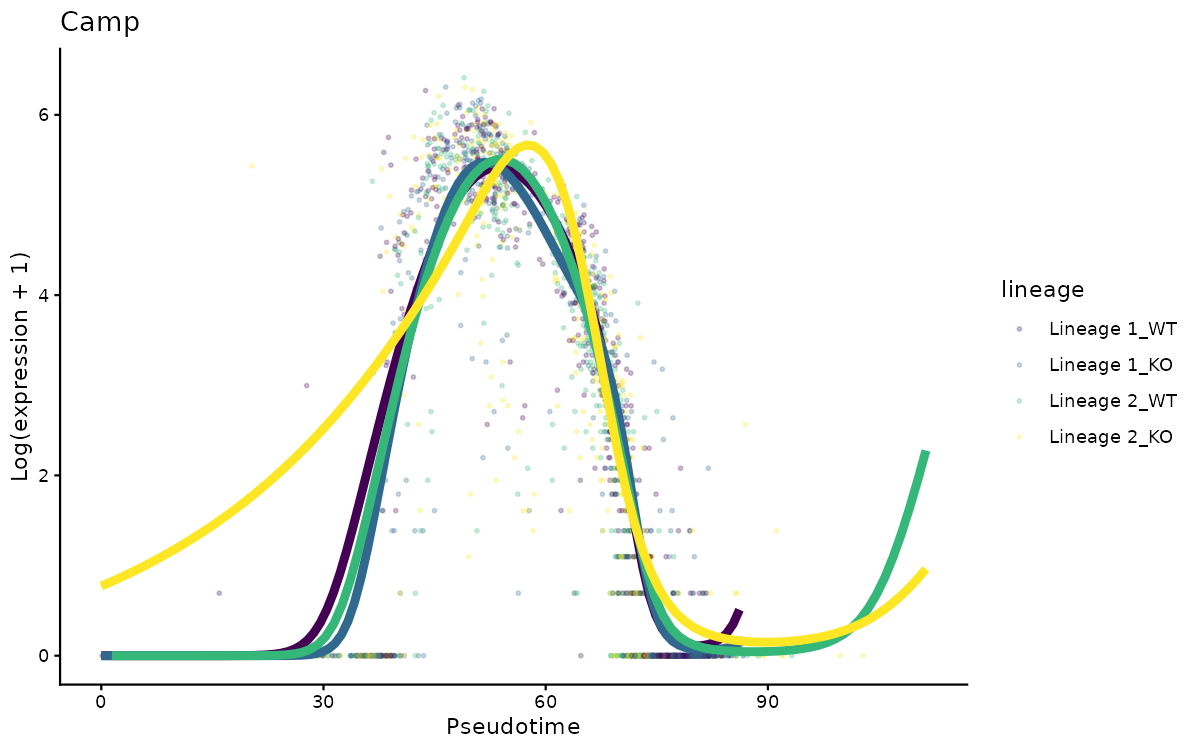

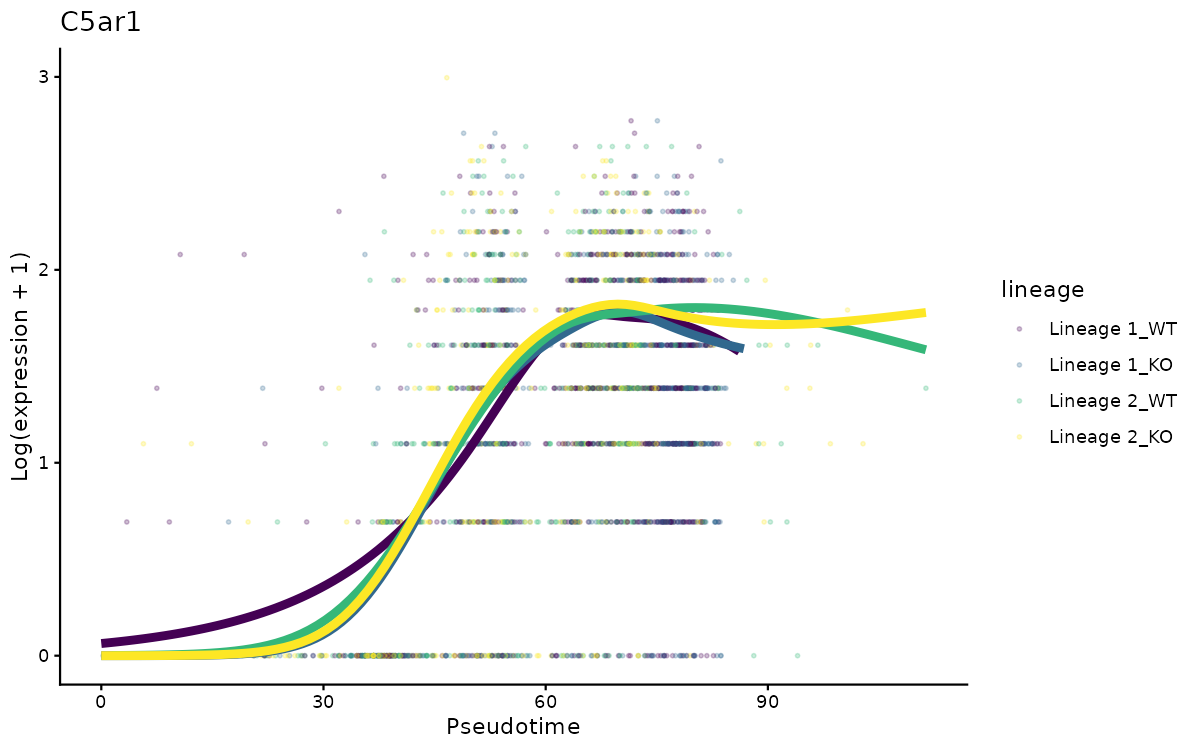

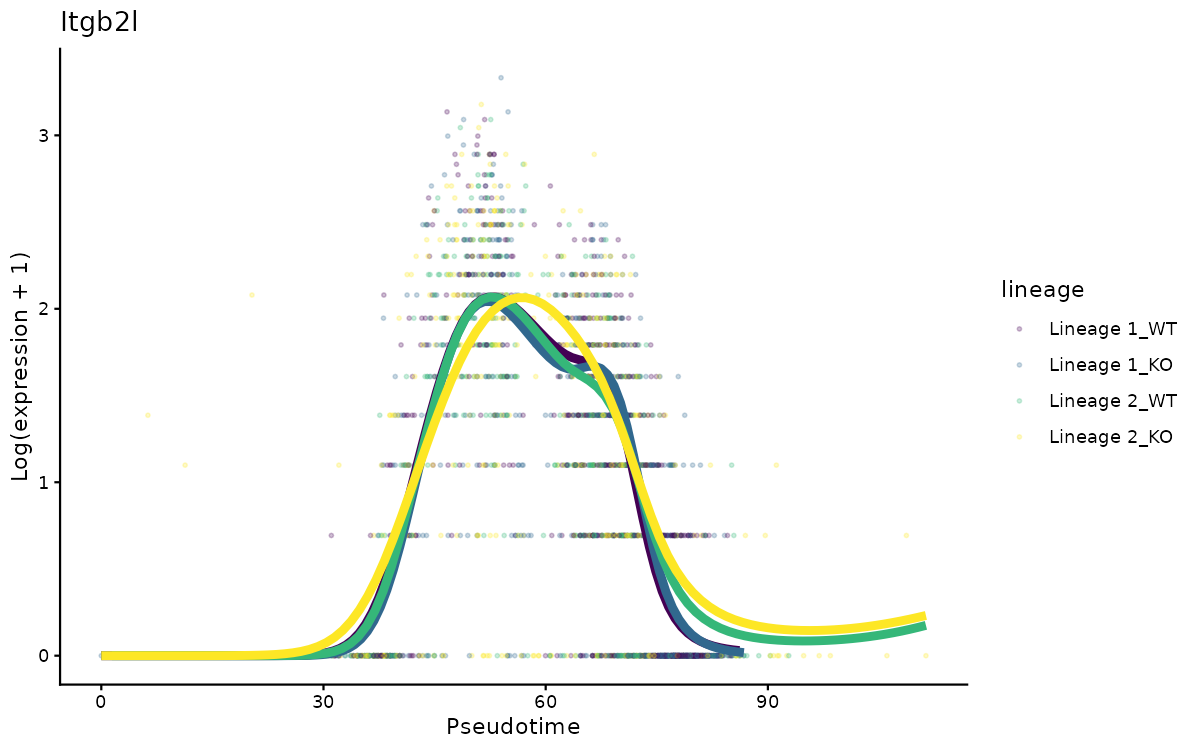

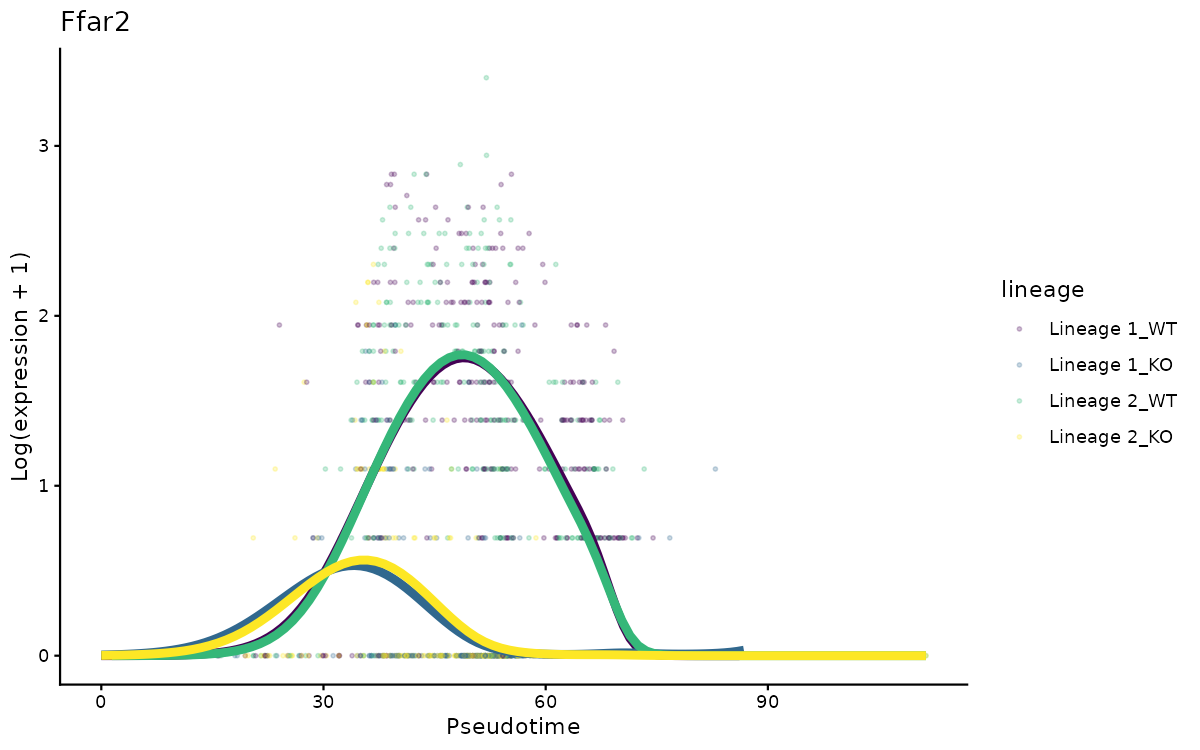

In [41]:
PlotTradeSeqGene("Camp")
PlotTradeSeqGene("C5ar1")
PlotTradeSeqGene("Itgb2l")
PlotTradeSeqGene("Ffar2")

In [51]:
def SaveTradeSeqSignificantPlots(
    adata,
    result_table,
    lineage_tests,
    counts_layer="QC_filtered",
    output_dir="tradeSeq_significant_plots",
    padj_cutoff=0.05,
    sample_cells=0.25,
    width=8,
    height=5,
):
    """
    Save tradeSeq smoother plots for all significant genes.

    adata : AnnData --> Dataset containing raw counts.
    result_table : DataFrame --> tradeSeq results containing gene and padj.
    lineage_tests : dict --> Selected-gene tradeSeq model.
    counts_layer : str --> Layer containing raw counts.
    output_dir : str --> Directory where plots are saved.
    padj_cutoff : float --> Adjusted p-value cutoff.
    sample_cells : float --> Fraction of cells displayed as points.
    width : float --> Figure width in inches.
    height : float --> Figure height in inches.

    Returns
    -------
    list[str] --> Genes successfully plotted.
    """
    import os
    import re
    import numpy as np
    from scipy import sparse
    from rpy2 import robjects as ro

    os.makedirs(output_dir, exist_ok=True)

    # Significant genes that are present in the fitted follow-up model
    significant_genes = (
        result_table
        .query("padj < @padj_cutoff")
        ["gene"]
        .drop_duplicates()
        .tolist()
    )

    model_genes = lineage_tests["genes"]
    significant_genes = [g for g in significant_genes if g in model_genes]

    # Reconstruct counts only for genes present in the fitted model
    gene_idx = adata.var_names.get_indexer(model_genes)

    if (gene_idx < 0).any():
        missing = np.array(model_genes)[gene_idx < 0]
        raise ValueError(f"Genes missing from adata: {missing.tolist()}")

    X = adata.layers[counts_layer][:, gene_idx]

    if not sparse.issparse(X):
        X = sparse.csr_matrix(X)

    X = X.T.tocoo()  # genes x cells

    ro.globalenv["save_i"] = ro.IntVector((X.row + 1).astype(int))
    ro.globalenv["save_j"] = ro.IntVector((X.col + 1).astype(int))
    ro.globalenv["save_x"] = ro.FloatVector(X.data.astype(float))
    ro.globalenv["save_ngenes"] = int(X.shape[0])
    ro.globalenv["save_ncells"] = int(X.shape[1])
    ro.globalenv["save_genes"] = ro.StrVector(model_genes)
    ro.globalenv["save_cells"] = ro.StrVector(adata.obs_names.astype(str))
    ro.globalenv["save_model"] = lineage_tests["model"]

    ro.r("""
        suppressPackageStartupMessages({
            library(Matrix)
            library(tradeSeq)
            library(ggplot2)
        })

        save_counts <- sparseMatrix(
            i=save_i,
            j=save_j,
            x=save_x,
            dims=c(save_ngenes, save_ncells)
        )

        rownames(save_counts) <- save_genes
        colnames(save_counts) <- save_cells

        names(save_model) <- rownames(save_model)
    """)

    saved = []

    for i, gene in enumerate(significant_genes, 1):
        filename = re.sub(r"[^A-Za-z0-9_.-]", "_", gene) + ".png"
        filepath = os.path.abspath(os.path.join(output_dir, filename))

        ro.globalenv["gene_save"] = gene
        ro.globalenv["file_save"] = filepath
        ro.globalenv["sample_save"] = float(sample_cells)
        ro.globalenv["width_save"] = float(width)
        ro.globalenv["height_save"] = float(height)

        try:
            ro.r("""
                p <- plotSmoothers(
                    save_model,
                    counts=save_counts,
                    gene=gene_save,
                    sample=sample_save,
                    border=FALSE,
                    alpha=0.20
                ) +
                    ggtitle(gene_save) +
                    theme_classic()

                ggsave(
                    filename=file_save,
                    plot=p,
                    width=width_save,
                    height=height_save,
                    dpi=300
                )
            """)

            saved.append(gene)
            print(f"[{i}/{len(significant_genes)}] Saved: {gene}")

        except Exception as e:
            print(f"[{i}/{len(significant_genes)}] FAILED: {gene} --> {e}")

    ro.r("""
        rm(
            save_counts,
            save_i,
            save_j,
            save_x
        )
        gc()
    """)

    print(f"\nSaved {len(saved)}/{len(significant_genes)} plots to:")
    print(os.path.abspath(output_dir))

    return saved

In [53]:
saved_genes = SaveTradeSeqSignificantPlots(
    adata=ad_sling,
    result_table=condition_slingshot_fc15,
    lineage_tests=lineage_tests,
    counts_layer="QC_filtered",
    output_dir="/media/tahila/DADOS/HD/2605_scNeu/scNeuFfar2/10sx.scNeuFfar2_trajectory/tradeSeq_fc15_significant_plots",
    padj_cutoff=0.05,
)

[1/30] Saved: Camp
[2/30] Saved: Ngp
[3/30] Saved: Ltf
[4/30] Saved: Cd177
[5/30] Saved: Wfdc21
[6/30] Saved: Lcn2
[7/30] Saved: Chil1
[8/30] Saved: Blvrb
[9/30] Saved: Gm34680
[10/30] Saved: Il1r2
[11/30] Saved: Lrg1
[12/30] Saved: Olfml2b
[13/30] Saved: Alox5
[14/30] Saved: C5ar1
[15/30] Saved: Itgb2l
[16/30] Saved: Pglyrp1
[17/30] Saved: Ptprt
[18/30] Saved: Mmp25
[19/30] Saved: Inhba
[20/30] Saved: Ifnlr1
[21/30] Saved: S100a9
[22/30] Saved: Igkc
[23/30] Saved: Cstdc4
[24/30] Saved: Tnfsf13b
[25/30] Saved: Fosb
[26/30] Saved: Cdca8
[27/30] Saved: Cd33
[28/30] Saved: Mmp9
[29/30] Saved: Klf4
[30/30] Saved: Hba-a2

Saved 30/30 plots to:
/media/tahila/DADOS/HD/2605_scNeu/scNeuFfar2/10sx.scNeuFfar2_trajectory/tradeSeq_fc15_significant_plots


In [54]:
for name, obj in list(globals().items()):
    if isinstance(obj, dict) and "model" in obj:
        print(name, "->", list(obj.keys()))

slingshot -> ['pseudotime', 'weights', 'lineages', 'model']
lineage_tests -> ['model', 'results', 'results_fc', 'genes', 'lineages', 'fc_threshold']
sample_dynamics -> ['model', 'counts', 'genes', 'samples', 'lineages']


In [55]:
for name in [
    "trade_result",
    "trade_slingshot",
    "trade_slingshot_final",
    "lineage_tests",
    "sample_dynamics",
]:
    print(name, "->", name in globals())

trade_result -> False
trade_slingshot -> False
trade_slingshot_final -> True
lineage_tests -> True
sample_dynamics -> True
